# Public review copy — MIS581 Capstone

This notebook is a sanitized publication copy of an executed development notebook. Local Windows paths were replaced with relative placeholders and embedded Census API configuration was changed to use the `CENSUS_API_KEY` environment variable. Historical error outputs were omitted; successful saved outputs were retained. The notebook has **not** been independently re-executed as a clean installation. It may require original source data, a compatible Python environment, and (for Notebook 08) PostgreSQL. Use the project README to understand dependencies and expected folder layout.


In [1]:

# ============================================================
# MIS581 CAPSTONE PROJECT
# MASTER NOTEBOOK INITIALIZATION
# ============================================================

# PURPOSE:
# Initialize Python libraries, project directories,
# and PostgreSQL connectivity after a Jupyter restart.
#
# Run this cell FIRST whenever opening the notebook.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT PYTHON LIBRARIES
# ------------------------------------------------------------

# File and directory management
from pathlib import Path
import os

# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Statistical analysis
from scipy import stats

# Data visualization
import matplotlib.pyplot as plt

# API requests
import requests

# Excel workbook processing
import openpyxl

# PostgreSQL connectivity
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Secure password input
from getpass import getpass


# ------------------------------------------------------------
# 2. DEFINE PROJECT DIRECTORIES
# ------------------------------------------------------------

project_dir = Path(
    r".."
)

data_dir = project_dir / "data"

raw_dir = data_dir / "raw"
processed_dir = data_dir / "processed"

# Source-specific directories
fhfa_dir = raw_dir / "fhfa"
bls_dir = raw_dir / "bls"
fred_dir = raw_dir / "fred"
census_dir = raw_dir / "census"

# Verify directories exist
required_dirs = [
    project_dir,
    data_dir,
    raw_dir,
    processed_dir
]

for directory in required_dirs:
    if not directory.is_dir():
        raise FileNotFoundError(
            f"Required directory not found: {directory}"
        )


# ------------------------------------------------------------
# 3. ESTABLISH POSTGRESQL CONNECTION
# ------------------------------------------------------------

db_password = getpass("PostgreSQL password: ")

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password=db_password,
    host="localhost",
    port=5432,
    database="mis581_capstone"
)

engine = create_engine(
    db_url,
    pool_pre_ping=True
)


# ------------------------------------------------------------
# 4. VERIFY DATABASE CONNECTIVITY
# ------------------------------------------------------------

with engine.connect() as conn:

    result = conn.execute(
        text("""
            SELECT
                current_database(),
                current_user,
                version()
        """)
    ).fetchone()

print("\nPOSTGRESQL CONNECTION")
print("=" * 60)

print("Database:", result[0])
print("User:", result[1])
print("PostgreSQL:", result[2].split(",")[0])


# ------------------------------------------------------------
# 5. VERIFY PROJECT ENVIRONMENT
# ------------------------------------------------------------

print("\nPROJECT ENVIRONMENT")
print("=" * 60)

print("Project directory:", project_dir)
print("Data directory:", data_dir)
print("Raw directory:", raw_dir)
print("Processed directory:", processed_dir)

print("\nPython libraries initialized successfully.")
print("PostgreSQL engine initialized successfully.")

print("\nMIS581 CAPSTONE ENVIRONMENT READY!")


PostgreSQL password:  ········



POSTGRESQL CONNECTION
Database: mis581_capstone
User: postgres
PostgreSQL: PostgreSQL 18.2 on x86_64-windows

PROJECT ENVIRONMENT
Project directory: <LOCAL_FILE_PATH>
Data directory: <LOCAL_FILE_PATH>
Raw directory: <LOCAL_FILE_PATH>
Processed directory: <LOCAL_FILE_PATH>

Python libraries initialized successfully.
PostgreSQL engine initialized successfully.

MIS581 CAPSTONE ENVIRONMENT READY!


In [2]:

# ============================================================
# MIS581 CAPSTONE - RESTORE ANALYTICAL DATAFRAMES
# Run AFTER the Master Initialization cell
# Recreates Steps 73, 74, 76, 78, 79 and 80
# ============================================================

# 1. Retrieve integrated data from PostgreSQL
from sqlalchemy import text

query = """
SELECT *
FROM analytics.vw_housing_market_annual
ORDER BY cbsa, year
"""

df_housing_analysis = pd.read_sql(
    text(query),
    con=engine
)

# 2. Recreate analytical baseline
df_housing_baseline = df_housing_analysis.copy(deep=True)

df_housing_baseline["cbsa"] = (
    df_housing_baseline["cbsa"]
    .astype("string")
    .str.strip()
    .str.zfill(5)
)

df_housing_baseline["year"] = (
    df_housing_baseline["year"].astype(int)
)

# 3. Normalize residential building permits
df_housing_working = df_housing_baseline.copy(deep=True)

df_housing_working["permits_per_1000"] = (
    df_housing_working["permits_total"]
    / df_housing_working["population"]
    * 1000
)

# 4. Restore previously validated annual CPI data
cpi_path = processed_dir / "cpi_u_annual_2005_2024.csv"

if not cpi_path.is_file():
    raise FileNotFoundError(
        f"Validated CPI file not found: {cpi_path}"
    )

df_cpi_annual = pd.read_csv(cpi_path)

df_cpi_annual["year"] = (
    df_cpi_annual["year"].astype(int)
)

# 5. Recreate inflation-adjusted income dataset
df_housing_real = df_housing_working.merge(
    df_cpi_annual[["year", "cpi_annual"]],
    on="year",
    how="left",
    validate="many_to_one"
)

cpi_2024 = df_cpi_annual.loc[
    df_cpi_annual["year"] == 2024,
    "cpi_annual"
].iloc[0]

df_housing_real["median_household_income_real_2024"] = (
    df_housing_real["median_household_income"]
    * cpi_2024
    / df_housing_real["cpi_annual"]
)

# 6. Recreate annual real-income growth
df_housing_model = (
    df_housing_real
    .sort_values(["cbsa", "year"])
    .reset_index(drop=True)
    .copy()
)

grouped = df_housing_model.groupby("cbsa")

df_housing_model["previous_year"] = (
    grouped["year"].shift(1)
)

df_housing_model["previous_real_income"] = (
    grouped["median_household_income_real_2024"].shift(1)
)

valid_growth = (
    (df_housing_model["year"]
     - df_housing_model["previous_year"] == 1)
    & df_housing_model[
        "median_household_income_real_2024"
    ].notna()
    & df_housing_model["previous_real_income"].notna()
    & (df_housing_model["previous_real_income"] > 0)
)

df_housing_model["real_income_growth_pct"] = np.where(
    valid_growth,
    (
        df_housing_model["median_household_income_real_2024"]
        / df_housing_model["previous_real_income"]
        - 1
    ) * 100,
    np.nan
)

# 7. Recreate regression samples
shared_variables = [
    "hpi_annual_change_pct",
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000"
]

level_variables = shared_variables + [
    "median_household_income_real_2024"
]

growth_variables = shared_variables + [
    "real_income_growth_pct"
]

df_model_income_level = df_housing_model.dropna(
    subset=level_variables
).copy()

df_model_income_growth = df_housing_model.dropna(
    subset=growth_variables
).copy()

df_model_common = df_housing_model.dropna(
    subset=level_variables + ["real_income_growth_pct"]
).copy()

# 8. Validate restoration
assert len(df_housing_analysis) == 140
assert df_housing_baseline["cbsa"].nunique() == 7
assert df_housing_baseline["year"].nunique() == 20
assert not df_housing_baseline.duplicated(
    ["cbsa", "year"]
).any()

assert len(df_cpi_annual) == 20
assert (df_cpi_annual["months_reported"] == 12).all()
assert np.isclose(cpi_2024, 313.689, atol=0.02)

assert df_housing_working["permits_per_1000"].count() == 133
assert df_housing_real[
    "median_household_income_real_2024"
].count() == 133
assert df_housing_model["real_income_growth_pct"].count() == 119

assert len(df_model_income_level) == 133
assert len(df_model_income_growth) == 119
assert len(df_model_common) == 119

# 9. Report restored DataFrames
print("MIS581 ANALYTICAL DATAFRAME RESTORATION")
print("=" * 60)

restored = {
    "df_housing_analysis": df_housing_analysis,
    "df_housing_baseline": df_housing_baseline,
    "df_housing_working": df_housing_working,
    "df_cpi_annual": df_cpi_annual,
    "df_housing_real": df_housing_real,
    "df_housing_model": df_housing_model,
    "df_model_income_level": df_model_income_level,
    "df_model_income_growth": df_model_income_growth,
    "df_model_common": df_model_common
}

for name, dataframe in restored.items():
    print(f"{name:30s} {dataframe.shape}")

print("\nAll validation checks passed.")
print("Analytical DataFrames are ready!")


MIS581 ANALYTICAL DATAFRAME RESTORATION
df_housing_analysis            (140, 17)
df_housing_baseline            (140, 17)
df_housing_working             (140, 18)
df_cpi_annual                  (20, 3)
df_housing_real                (140, 20)
df_housing_model               (140, 23)
df_model_income_level          (133, 23)
df_model_income_growth         (119, 23)
df_model_common                (119, 23)

All validation checks passed.
Analytical DataFrames are ready!


In [3]:

# ============================================================
# MIS581 - FIGURE 1 PRE-VISUALIZATION VALIDATION
# ============================================================

df_fig1 = df_housing_baseline[
    ["cbsa", "metro_name", "year", "hpi_annual_change_pct"]
].copy()

# Ensure HPI changes are numeric
df_fig1["hpi_annual_change_pct"] = pd.to_numeric(
    df_fig1["hpi_annual_change_pct"],
    errors="coerce"
)

# Check coverage and values by metropolitan area
validation = (
    df_fig1.groupby(["cbsa", "metro_name"])
    .agg(
        observations=("year", "count"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        missing_hpi=("hpi_annual_change_pct",
                     lambda x: x.isna().sum()),
        min_hpi_change=("hpi_annual_change_pct", "min"),
        max_hpi_change=("hpi_annual_change_pct", "max")
    )
    .reset_index()
)

print("FIGURE 1 - DATA VALIDATION")
print("=" * 65)
print(validation.to_string(index=False))

print("\nOverall HPI change summary:")
print(df_fig1["hpi_annual_change_pct"].describe().round(3))

# Confirm chart readiness
assert len(df_fig1) == 140
assert df_fig1["cbsa"].nunique() == 7
assert (validation["observations"] == 20).all()
assert (validation["first_year"] == 2005).all()
assert (validation["last_year"] == 2024).all()
assert (validation["missing_hpi"] == 0).all()
assert not df_fig1.duplicated(["cbsa", "year"]).any()

print("\nFigure 1 data validation PASSED.")


FIGURE 1 - DATA VALIDATION
 cbsa                                     metro_name  observations  first_year  last_year  missing_hpi  min_hpi_change  max_hpi_change
16700                Charleston-North Charleston, SC            20        2005       2024            0       -7.068486       21.445774
19100                Dallas-Fort Worth-Arlington, TX            20        2005       2024            0       -2.005370       22.011155
28140                             Kansas City, MO-KS            20        2005       2024            0       -3.358621       15.409717
29820               Las Vegas-Henderson-Paradise, NV            20        2005       2024            0      -26.498594       21.992856
34980 Nashville-Davidson--Murfreesboro--Franklin, TN            20        2005       2024            0       -2.860613       23.824820
35620          New York-Newark-Jersey City, NY-NJ-PA            20        2005       2024            0       -6.438337       15.440440
41860             San Franci

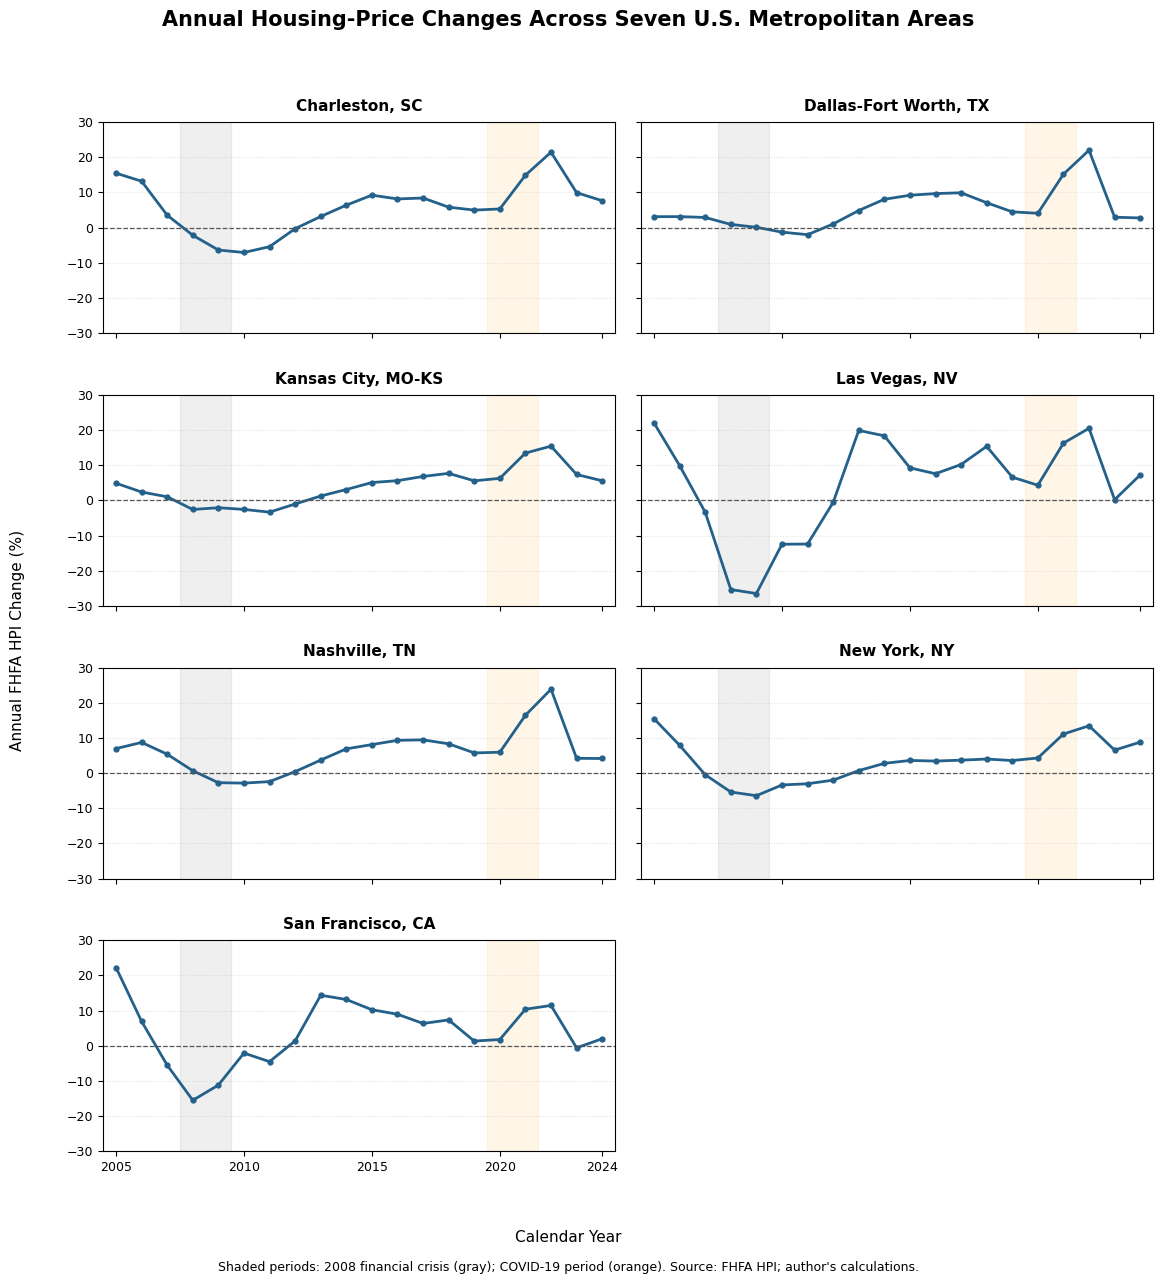

Figure saved to: <LOCAL_FILE_PATH>


In [4]:

# ============================================================
# MIS581 CAPSTONE - FIGURE 1
# Annual FHFA HPI Changes by Metropolitan Area, 2005-2024
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# Prepare visualization dataset
df_plot = df_fig1.copy()

metro_labels = {
    "16700": "Charleston, SC",
    "19100": "Dallas-Fort Worth, TX",
    "28140": "Kansas City, MO-KS",
    "29820": "Las Vegas, NV",
    "34980": "Nashville, TN",
    "35620": "New York, NY",
    "41860": "San Francisco, CA"
}

df_plot["cbsa"] = df_plot["cbsa"].astype(str).str.strip()

# Shared vertical limits for valid comparisons
y_min = -30
y_max = 30

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 13),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, (cbsa, label) in enumerate(metro_labels.items()):

    ax = axes[i]

    metro_data = (
        df_plot[df_plot["cbsa"] == cbsa]
        .sort_values("year")
    )

    # Financial crisis period
    ax.axvspan(
        2007.5, 2009.5,
        color="gray",
        alpha=0.12
    )

    # Pandemic period
    ax.axvspan(
        2019.5, 2021.5,
        color="orange",
        alpha=0.09
    )

    # Annual HPI percentage change
    ax.plot(
        metro_data["year"],
        metro_data["hpi_annual_change_pct"],
        color="#24618A",
        linewidth=2,
        marker="o",
        markersize=3.5
    )

    # Zero-growth reference
    ax.axhline(
        y=0,
        color="#555555",
        linestyle="--",
        linewidth=0.9
    )

    ax.set_title(
        label,
        fontsize=11,
        fontweight="bold",
        pad=8
    )

    ax.set_ylim(y_min, y_max)
    ax.set_xlim(2004.5, 2024.5)

    ax.set_xticks([2005, 2010, 2015, 2020, 2024])
    ax.yaxis.set_major_locator(
        mticker.MultipleLocator(10)
    )

    ax.grid(
        axis="y",
        linestyle=":",
        alpha=0.35
    )

    ax.tick_params(
        axis="both",
        labelsize=9
    )

# Hide unused eighth panel
axes[7].axis("off")

# Shared labels
fig.supxlabel(
    "Calendar Year",
    fontsize=11,
    y=0.035
)

fig.supylabel(
    "Annual FHFA HPI Change (%)",
    fontsize=11,
    x=0.035
)

fig.suptitle(
    "Annual Housing-Price Changes Across Seven U.S. Metropolitan Areas",
    fontsize=15,
    fontweight="bold",
    y=0.985
)

fig.text(
    0.5, 0.015,
    "Shaded periods: 2008 financial crisis (gray); COVID-19 period (orange). "
    "Source: FHFA HPI; author's calculations.",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0.045, 0.055, 1, 0.955],
    h_pad=2.2,
    w_pad=1.5
)

# Save high-resolution figure
output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "figure1_msa_hpi_panel.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Figure saved to: {figure_path.resolve()}")


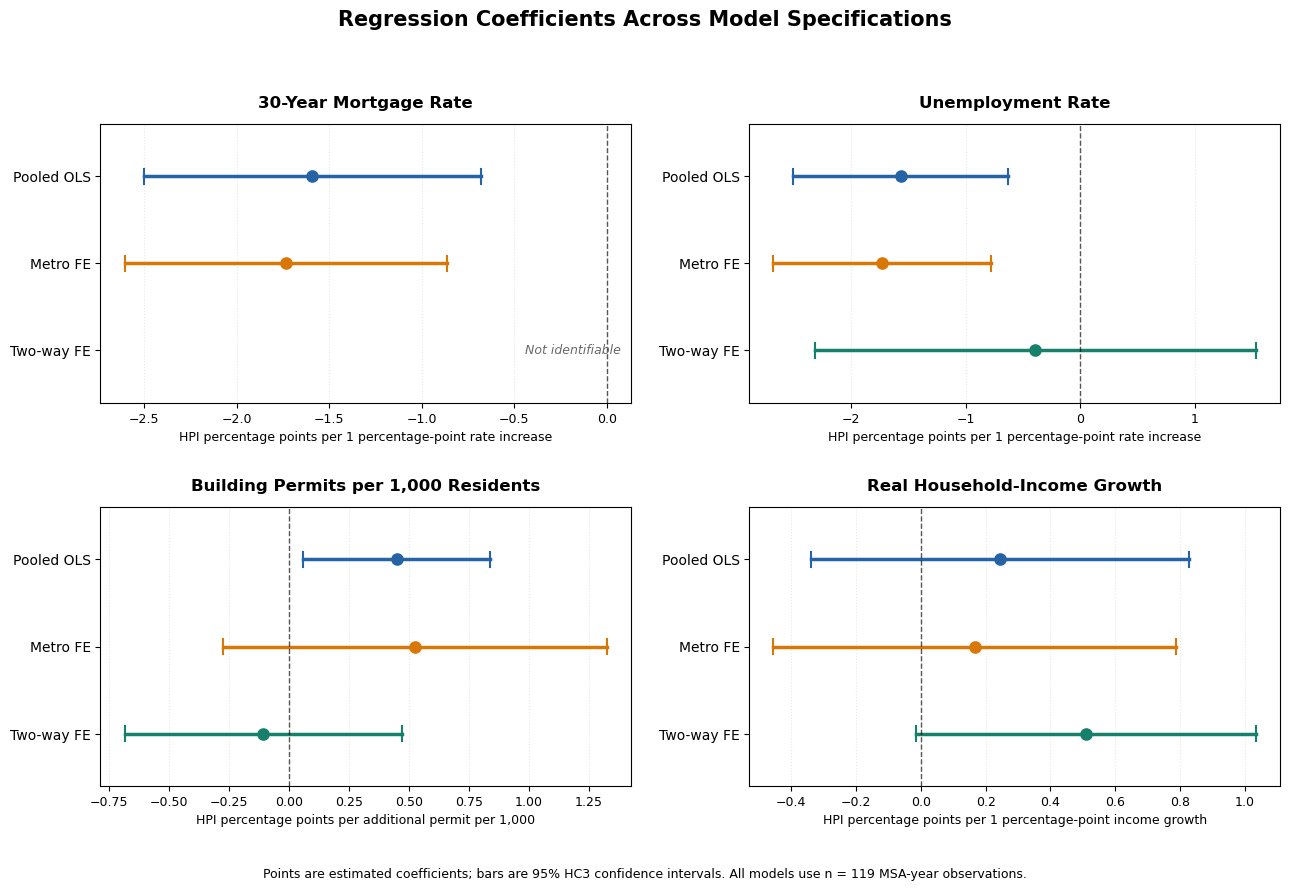

Figure saved to: <LOCAL_FILE_PATH>

REGRESSION COEFFICIENT VERIFICATION

Pooled OLS | n = 119
  mortgage_rate_30yr_annual           beta= -1.5918  p=0.0006
  unemployment_rate_annual            beta= -1.5696  p=0.0011
  permits_per_1000                    beta=  0.4488  p=0.0242
  real_income_growth_pct              beta=  0.2436  p=0.4126

Metro FE | n = 119
  mortgage_rate_30yr_annual           beta= -1.7353  p=0.0001
  unemployment_rate_annual            beta= -1.7319  p=0.0003
  permits_per_1000                    beta=  0.5253  p=0.1976
  real_income_growth_pct              beta=  0.1669  p=0.5988

Two-way FE | n = 119
  mortgage_rate_30yr_annual           Not identifiable
  unemployment_rate_annual            beta= -0.3920  p=0.6901
  permits_per_1000                    beta= -0.1077  p=0.7145
  real_income_growth_pct              beta=  0.5090  p=0.0575


In [5]:

# ============================================================
# MIS581 CAPSTONE - FIGURE 2
# Regression Coefficient Comparison Across Model Specifications
# Recreates the models from Notebook 08, Steps 83-85
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

# 1. Prepare the common regression sample
df_fig2 = df_model_common.copy()

df_fig2["cbsa"] = df_fig2["cbsa"].astype(str).str.strip()
df_fig2["year"] = df_fig2["year"].astype(int)

assert len(df_fig2) == 119
assert df_fig2["cbsa"].nunique() == 7

# 2. Recreate the regression models
formula_pooled = (
    "hpi_annual_change_pct ~ "
    "mortgage_rate_30yr_annual + "
    "unemployment_rate_annual + "
    "permits_per_1000 + "
    "real_income_growth_pct"
)

formula_metro = formula_pooled + " + C(cbsa)"

formula_two_way = (
    "hpi_annual_change_pct ~ "
    "unemployment_rate_annual + "
    "permits_per_1000 + "
    "real_income_growth_pct + "
    "C(cbsa) + C(year)"
)

models = {
    "Pooled OLS": smf.ols(
        formula_pooled, data=df_fig2
    ).fit(cov_type="HC3"),

    "Metro FE": smf.ols(
        formula_metro, data=df_fig2
    ).fit(cov_type="HC3"),

    "Two-way FE": smf.ols(
        formula_two_way, data=df_fig2
    ).fit(cov_type="HC3")
}

# 3. Confirm the models match our earlier notebook
assert np.isclose(
    models["Pooled OLS"].params["mortgage_rate_30yr_annual"],
    -1.5918, atol=0.001
)

assert np.isclose(
    models["Metro FE"].params["unemployment_rate_annual"],
    -1.7319, atol=0.001
)

assert np.isclose(
    models["Two-way FE"].params["real_income_growth_pct"],
    0.5090, atol=0.001
)

# 4. Define the four predictor panels
predictors = {
    "mortgage_rate_30yr_annual":
        ("30-Year Mortgage Rate",
         "HPI percentage points per 1 percentage-point rate increase"),

    "unemployment_rate_annual":
        ("Unemployment Rate",
         "HPI percentage points per 1 percentage-point rate increase"),

    "permits_per_1000":
        ("Building Permits per 1,000 Residents",
         "HPI percentage points per additional permit per 1,000"),

    "real_income_growth_pct":
        ("Real Household-Income Growth",
         "HPI percentage points per 1 percentage-point income growth")
}

model_names = ["Pooled OLS", "Metro FE", "Two-way FE"]

colors = {
    "Pooled OLS": "#2563A6",
    "Metro FE": "#D97706",
    "Two-way FE": "#16806A"
}

# 5. Create the four-panel figure
fig, axes = plt.subplots(
    2, 2, figsize=(13, 9)
)

axes = axes.flatten()

for ax, (variable, (title, xlabel)) in zip(
    axes, predictors.items()
):
    for i, model_name in enumerate(model_names):

        model = models[model_name]

        # Mortgage rate is excluded from two-way FE
        if variable not in model.params.index:
            ax.text(
                0.98, i,
                "Not identifiable",
                transform=ax.get_yaxis_transform(),
                ha="right",
                va="center",
                fontsize=9,
                color="dimgray",
                style="italic"
            )
            continue

        coefficient = model.params[variable]
        lower, upper = model.conf_int(
            alpha=0.05
        ).loc[variable]

        # Confidence interval
        ax.plot(
            [lower, upper], [i, i],
            color=colors[model_name],
            linewidth=2.5
        )

        # End caps
        ax.plot(
            [lower, lower], [i-0.09, i+0.09],
            color=colors[model_name],
            linewidth=1.5
        )
        ax.plot(
            [upper, upper], [i-0.09, i+0.09],
            color=colors[model_name],
            linewidth=1.5
        )

        # Coefficient point
        ax.scatter(
            coefficient, i,
            color=colors[model_name],
            s=65,
            zorder=3
        )

    # Zero-effect reference
    ax.axvline(
        0, color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.65
    )

    ax.set_yticks(range(3))
    ax.set_yticklabels(model_names, fontsize=10)
    ax.invert_yaxis()
    ax.set_ylim(2.6, -0.6)

    ax.set_title(
        title, fontsize=12,
        fontweight="bold", pad=12
    )

    ax.set_xlabel(xlabel, fontsize=9)

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.3
    )

    ax.tick_params(axis="x", labelsize=9)

fig.suptitle(
    "Regression Coefficients Across Model Specifications",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.015,
    "Points are estimated coefficients; bars are 95% HC3 confidence intervals. "
    "All models use n = 119 MSA-year observations.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.055, 1, 0.94],
                 h_pad=2.5, w_pad=2)

# 6. Save publication-quality figure
output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = (
    output_dir / "figure2_regression_coefficient_panels.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved to:", figure_path.resolve())

# 7. Print exact estimates for our review
print("\nREGRESSION COEFFICIENT VERIFICATION")
print("=" * 70)

for model_name, model in models.items():
    print(f"\n{model_name} | n = {int(model.nobs)}")
    for variable in predictors:
        if variable in model.params.index:
            print(
                f"  {variable:35s} "
                f"beta={model.params[variable]:8.4f}  "
                f"p={model.pvalues[variable]:.4f}"
            )
        else:
            print(f"  {variable:35s} Not identifiable")


Correlation verification PASSED.


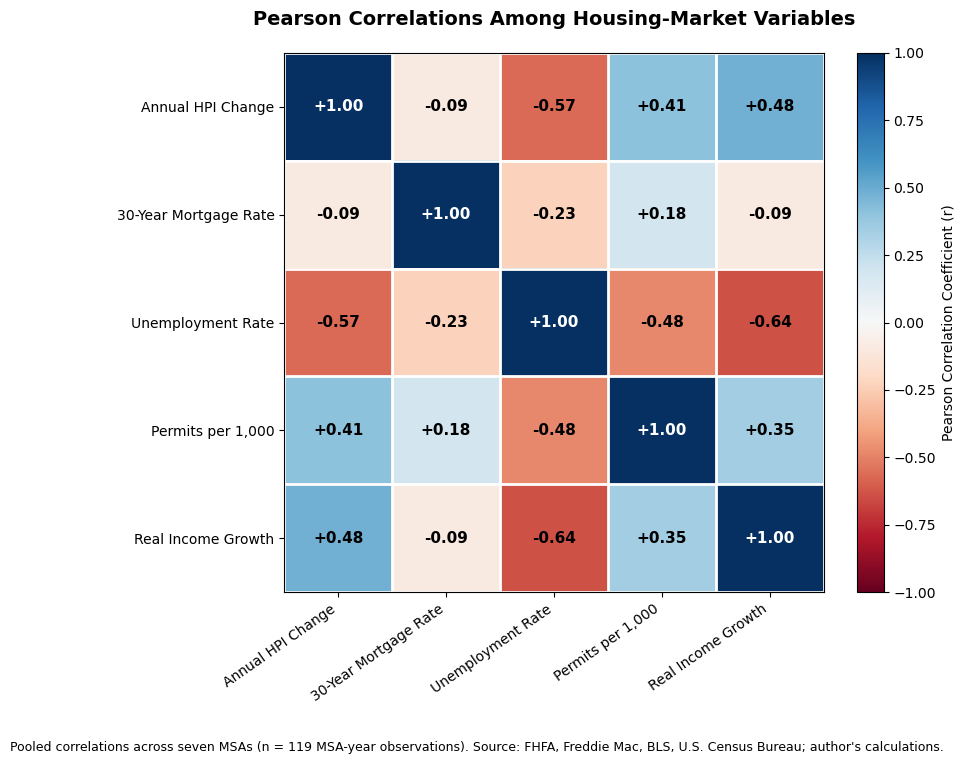


PEARSON CORRELATION MATRIX
                       Annual HPI Change  30-Year Mortgage Rate  Unemployment Rate  Permits per 1,000  Real Income Growth
Annual HPI Change                  1.000                 -0.087             -0.570              0.412               0.480
30-Year Mortgage Rate             -0.087                  1.000             -0.228              0.181              -0.092
Unemployment Rate                 -0.570                 -0.228              1.000             -0.484              -0.637
Permits per 1,000                  0.412                  0.181             -0.484              1.000               0.348
Real Income Growth                 0.480                 -0.092             -0.637              0.348               1.000

Figure saved to: <LOCAL_FILE_PATH>


In [6]:

# ============================================================
# MIS581 CAPSTONE - FIGURE 3
# Pearson Correlation Heatmap
# Seven MSAs | Common Regression Sample | n = 119
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Define the analytical variables
variables = {
    "hpi_annual_change_pct": "Annual HPI Change",
    "mortgage_rate_30yr_annual": "30-Year Mortgage Rate",
    "unemployment_rate_annual": "Unemployment Rate",
    "permits_per_1000": "Permits per 1,000",
    "real_income_growth_pct": "Real Income Growth"
}

# 2. Prepare the common analytical sample
df_fig3 = df_model_common[
    list(variables.keys())
].copy()

for column in df_fig3.columns:
    df_fig3[column] = pd.to_numeric(
        df_fig3[column], errors="coerce"
    )

assert len(df_fig3) == 119
assert not df_fig3.isna().any().any()

# 3. Calculate Pearson correlation coefficients
correlation_matrix = df_fig3.corr(
    method="pearson"
)

# 4. Validate against earlier documented results
expected_hpi_correlations = {
    "mortgage_rate_30yr_annual": -0.087,
    "unemployment_rate_annual": -0.570,
    "permits_per_1000": 0.412,
    "real_income_growth_pct": 0.480
}

for variable, expected in expected_hpi_correlations.items():
    observed = correlation_matrix.loc[
        "hpi_annual_change_pct", variable
    ]

    assert np.isclose(
        observed, expected, atol=0.005
    ), f"Correlation mismatch for {variable}: {observed}"

print("Correlation verification PASSED.")

# 5. Rename variables for chart readability
correlation_display = correlation_matrix.rename(
    index=variables,
    columns=variables
)

# 6. Create heatmap
fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(
    correlation_display.values,
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    aspect="equal"
)

# Axis labels
ax.set_xticks(range(len(variables)))
ax.set_yticks(range(len(variables)))

ax.set_xticklabels(
    correlation_display.columns,
    rotation=35,
    ha="right",
    fontsize=10
)

ax.set_yticklabels(
    correlation_display.index,
    fontsize=10
)

# 7. Add correlation values inside cells
for i in range(len(variables)):
    for j in range(len(variables)):

        value = correlation_display.iloc[i, j]

        text_color = (
            "white" if abs(value) >= 0.65
            else "black"
        )

        ax.text(
            j, i,
            f"{value:+.2f}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=text_color
        )

# 8. Add cell borders
ax.set_xticks(
    np.arange(-0.5, len(variables), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(variables), 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=2
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# 9. Color scale
colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Pearson Correlation Coefficient (r)",
    fontsize=10
)

# 10. Title and source note
ax.set_title(
    "Pearson Correlations Among Housing-Market Variables",
    fontsize=14,
    fontweight="bold",
    pad=20
)

fig.text(
    0.5, 0.015,
    "Pooled correlations across seven MSAs (n = 119 MSA-year observations). "
    "Source: FHFA, Freddie Mac, BLS, U.S. Census Bureau; author's calculations.",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0.055, 1, 0.96]
)

# 11. Save figure
output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = (
    output_dir / "figure3_correlation_heatmap.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 12. Print numerical results
print("\nPEARSON CORRELATION MATRIX")
print("=" * 65)
print(correlation_display.round(3).to_string())

print("\nFigure saved to:", figure_path.resolve())


In [3]:

from pathlib import Path
import pandas as pd

# MIS581 Capstone - Step 6
# Verify the Building Permits export before loading

data_dir = Path(
    r"../data"
)

csv_path = data_dir / "building_permits_msa_2005_2024.csv"

print("File exists:", csv_path.exists())

if csv_path.exists():
    df_permits = pd.read_csv(
        csv_path,
        dtype={"cbsa": "string"}
    )

    print("Dataset shape:", df_permits.shape)
    print("\nColumn names:")
    print(df_permits.columns.tolist())

    print("\nFirst five records:")
    display(df_permits.head())


File exists: True
Dataset shape: (140, 9)

Column names:
['year', 'cbsa', 'metro_name', 'permits_total', 'units_1', 'units_2', 'units_3_4', 'units_5_plus', 'structures_5_plus']

First five records:


,year,cbsa,metro_name,permits_total,units_1,units_2,units_3_4,units_5_plus,structures_5_plus
0,2005,16700,"Charleston-North Charleston,* SC",10818,8084,156,129,2449,155
1,2005,19100,"Dallas-Fort Worth-Arlington,* TX",59895,49489,442,152,9812,509
2,2005,28140,"Kansas City,* MO-KS",15218,12118,528,749,1823,109
3,2005,29820,"Las Vegas-Paradise,* NV",39237,30479,96,1155,7507,348
4,2005,34980,"Nashville-Davidson--Murfreesboro,* TN",16654,14074,322,75,2183,123


In [2]:

# MIS581 Capstone - Step 7
# Check PostgreSQL connectivity libraries

import importlib.util

for package in ["sqlalchemy", "psycopg2", "psycopg"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")


sqlalchemy: Installed
psycopg2: Not installed
psycopg: Installed


In [3]:

# MIS581 Capstone - Step 8
# Install PostgreSQL driver into the active Jupyter environment

%pip install "psycopg[binary]"


Note: you may need to restart the kernel to use updated packages.


In [4]:

# MIS581 Capstone - Step 9
# Test Python-to-PostgreSQL connectivity

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

# Enter your PostgreSQL password securely
db_password = getpass("PostgreSQL password: ")

# Build the connection URL
db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password=db_password,
    host="localhost",
    port=5432,
    database="mis581_capstone"
)

# Create the SQLAlchemy engine
engine = create_engine(db_url)

# Test the connection
with engine.connect() as conn:
    result = conn.execute(
        text("SELECT current_database(), current_user, version()")
    ).fetchone()

    print("Connected database:", result[0])
    print("Connected user:", result[1])
    print("PostgreSQL version:", result[2].split(",")[0])


PostgreSQL password:  ········


Connected database: mis581_capstone
Connected user: postgres
PostgreSQL version: PostgreSQL 18.2 on x86_64-windows


In [5]:

# MIS581 Capstone - Step 10
# Load Building Permits CSV into PostgreSQL staging

from sqlalchemy import text

# Reload source data if the kernel was restarted
df_permits = pd.read_csv(
    csv_path,
    dtype={"cbsa": "string"}
)

# Verify expected columns before loading
expected_columns = [
    "year", "cbsa", "metro_name", "permits_total",
    "units_1", "units_2", "units_3_4",
    "units_5_plus", "structures_5_plus"
]

assert df_permits.columns.tolist() == expected_columns, \
    "CSV columns do not match the staging table."

assert len(df_permits) == 140, \
    "Unexpected number of Building Permits records."

# Replace the staging snapshot within one transaction
with engine.begin() as conn:

    conn.execute(
        text("DELETE FROM staging.building_permits")
    )

    df_permits.to_sql(
        name="building_permits",
        con=conn,
        schema="staging",
        if_exists="append",
        index=False,
        chunksize=500
    )

    row_count = conn.execute(
        text("SELECT COUNT(*) FROM staging.building_permits")
    ).scalar_one()

    assert row_count == len(df_permits), \
        "PostgreSQL row count does not match source CSV."

print("Building Permits staging load successful!")
print("Source records:", len(df_permits))
print("PostgreSQL staging records:", row_count)


Building Permits staging load successful!
Source records: 140
PostgreSQL staging records: 140


In [1]:

# MIS581 Capstone - Step 16
# Identify available FHFA source and prepared files

from pathlib import Path

data_dir = Path(
    r"../data"
)

fhfa_files = sorted(
    path for path in data_dir.rglob("*")
    if path.is_file()
    and (
        "fhfa" in path.name.lower()
        or "hpi" in path.name.lower()
    )
)

print("FHFA-related files found:", len(fhfa_files))

for path in fhfa_files:
    print(path.relative_to(data_dir))


FHFA-related files found: 1
raw\fhfa\hpi_at_metro.csv


In [2]:

# MIS581 Capstone - Step 17
# Load FHFA data and isolate the seven selected CBSAs

import pandas as pd

fhfa_path = data_dir / "raw" / "fhfa" / "hpi_at_metro.csv"

fhfa_columns = [
    "metro",
    "cbsa",
    "year",
    "quarter",
    "hpi",
    "annual_change"
]

df_fhfa = pd.read_csv(
    fhfa_path,
    header=None,
    names=fhfa_columns,
    na_values="-",
    dtype={"cbsa": "string"}
)

selected_cbsas = [
    "16700", "19100", "28140", "29820",
    "34980", "35620", "41860"
]

df_fhfa_selected = df_fhfa.loc[
    df_fhfa["cbsa"].isin(selected_cbsas)
    & df_fhfa["year"].between(2004, 2024)
].copy()

print("Selected records:", len(df_fhfa_selected))
print("Unique CBSAs:", df_fhfa_selected["cbsa"].nunique())
print("Year range:",
      df_fhfa_selected["year"].min(),
      "to",
      df_fhfa_selected["year"].max())

print("\nQuarterly observations by CBSA:")
display(
    df_fhfa_selected.groupby("cbsa")
    .agg(
        observations=("hpi", "size"),
        valid_hpi=("hpi", "count"),
        unique_years=("year", "nunique")
    )
)


Selected records: 336
Unique CBSAs: 4
Year range: 2004 to 2024

Quarterly observations by CBSA:


,observations,valid_hpi,unique_years
cbsa,,,
16700,84,84,21
28140,84,84,21
29820,84,84,21
34980,84,84,21


In [3]:

# MIS581 Capstone - Step 18
# Investigate missing metropolitan areas in FHFA data

missing_metro_names = [
    "Dallas",
    "New York",
    "San Francisco"
]

for metro_name in missing_metro_names:

    matches = df_fhfa[
        df_fhfa["metro"].astype(str).str.contains(
            metro_name,
            case=False,
            na=False,
            regex=False
        )
    ]

    print(f"\n{metro_name}:")
    print("Matching records:", len(matches))

    if not matches.empty:
        display(
            matches[["metro", "cbsa"]]
            .drop_duplicates()
            .head(20)
        )



Dallas:
Matching records: 206


,metro,cbsa
18128,"Dallas-Plano-Irving, TX (MSAD)",19124



New York:
Matching records: 206


,metro,cbsa
54384,"New York-Jersey City-White Plains, NY-NJ (MSAD)",35614



San Francisco:
Matching records: 206


,metro,cbsa
67774,"San Francisco-San Mateo-Redwood City, CA (MSAD)",41884


In [4]:

# MIS581 Capstone - Step 19
# Examine related FHFA metropolitan divisions

search_terms = [
    "Dallas", "Fort Worth",
    "New York", "Newark",
    "San Francisco", "Oakland"
]

matches = df_fhfa.loc[
    df_fhfa["metro"].astype(str).str.contains(
        "|".join(search_terms),
        case=False,
        na=False
    ),
    ["metro", "cbsa"]
].drop_duplicates()

display(
    matches.sort_values(["metro", "cbsa"])
    .reset_index(drop=True)
)


,metro,cbsa
0,"Dallas-Plano-Irving, TX (MSAD)",19124
1,"Fort Worth-Arlington-Grapevine, TX (MSAD)",23104
2,"New York-Jersey City-White Plains, NY-NJ (MSAD)",35614
3,"Newark, NJ (MSAD)",35084
4,"Oakland-Fremont-Berkeley, CA (MSAD)",36084
5,"San Francisco-San Mateo-Redwood City, CA (MSAD)",41884


In [5]:

# MIS581 Capstone - Step 21
# Load FHFA combined-MSA HPI data for the three missing CBSAs

fhfa_multid_path = (
    data_dir / "raw" / "fhfa" / "hpi_at_multid_metro.xlsx"
)

df_fhfa_multid = pd.read_excel(
    fhfa_multid_path,
    header=3,
    dtype={"cbsa_code": "string"}
)

missing_cbsas = ["19100", "35620", "41860"]

df_fhfa_multid_selected = df_fhfa_multid.loc[
    df_fhfa_multid["cbsa_code"].isin(missing_cbsas)
    & df_fhfa_multid["yr"].between(2004, 2024)
].copy()

print("Selected records:", len(df_fhfa_multid_selected))
print("Unique CBSAs:", df_fhfa_multid_selected["cbsa_code"].nunique())

display(
    df_fhfa_multid_selected.groupby("cbsa_code")
    .agg(
        observations=("index_nsa", "size"),
        valid_hpi=("index_nsa", "count"),
        unique_years=("yr", "nunique")
    )
)


Selected records: 252
Unique CBSAs: 3


,observations,valid_hpi,unique_years
cbsa_code,,,
19100,84,84,21
35620,84,84,21
41860,84,84,21


In [6]:

# MIS581 Capstone - Step 22
# Standardize and combine FHFA quarterly HPI sources

# Four metropolitan areas from the original FHFA CSV
df_fhfa_original = df_fhfa_selected[
    ["cbsa", "year", "quarter", "hpi"]
].copy()

df_fhfa_original["source"] = "FHFA Original Metro CSV"

# Three metropolitan areas from the combined-MSA workbook
df_fhfa_combined_msa = (
    df_fhfa_multid_selected[
        ["cbsa_code", "yr", "qtr", "index_nsa"]
    ]
    .rename(columns={
        "cbsa_code": "cbsa",
        "yr": "year",
        "qtr": "quarter",
        "index_nsa": "hpi"
    })
    .copy()
)

df_fhfa_combined_msa["source"] = "FHFA Combined MSA XLSX"

# Combine both sources
df_fhfa_quarterly = pd.concat(
    [df_fhfa_original, df_fhfa_combined_msa],
    ignore_index=True
)

# Normalize identifiers and numeric fields
df_fhfa_quarterly["cbsa"] = (
    df_fhfa_quarterly["cbsa"].astype("string").str.strip()
)

for column in ["year", "quarter", "hpi"]:
    df_fhfa_quarterly[column] = pd.to_numeric(
        df_fhfa_quarterly[column],
        errors="coerce"
    )

# Validate combined quarterly dataset
print("Total quarterly records:", len(df_fhfa_quarterly))
print("Unique CBSAs:", df_fhfa_quarterly["cbsa"].nunique())
print("Unique years:", df_fhfa_quarterly["year"].nunique())

print(
    "Duplicate CBSA-year-quarter records:",
    df_fhfa_quarterly.duplicated(
        subset=["cbsa", "year", "quarter"]
    ).sum()
)

print("\nMissing values:")
print(
    df_fhfa_quarterly[
        ["cbsa", "year", "quarter", "hpi"]
    ].isna().sum()
)

print("\nRecords by source:")
display(
    df_fhfa_quarterly.groupby("source")
    .size()
    .reset_index(name="records")
)

print("\nRecords by CBSA:")
display(
    df_fhfa_quarterly.groupby("cbsa")
    .agg(
        observations=("hpi", "size"),
        valid_hpi=("hpi", "count"),
        years=("year", "nunique")
    )
)


Total quarterly records: 588
Unique CBSAs: 7
Unique years: 21
Duplicate CBSA-year-quarter records: 0

Missing values:
cbsa       0
year       0
quarter    0
hpi        0
dtype: int64

Records by source:


,source,records
0,FHFA Combined MSA XLSX,252
1,FHFA Original Metro CSV,336



Records by CBSA:


,observations,valid_hpi,years
cbsa,,,
16700,84,84,21
19100,84,84,21
28140,84,84,21
29820,84,84,21
34980,84,84,21
35620,84,84,21
41860,84,84,21


In [7]:

# MIS581 Capstone - Step 23
# Calculate annual FHFA HPI and year-over-year percentage change

# Confirm complete quarterly coverage for every CBSA-year
quarter_validation = (
    df_fhfa_quarterly
    .groupby(["cbsa", "year"])
    .agg(
        quarter_count=("quarter", "nunique"),
        observation_count=("hpi", "size")
    )
    .reset_index()
)

incomplete_years = quarter_validation.loc[
    (quarter_validation["quarter_count"] != 4)
    | (quarter_validation["observation_count"] != 4)
]

print("Incomplete CBSA-year combinations:", len(incomplete_years))

if not incomplete_years.empty:
    display(incomplete_years)
    raise ValueError("Incomplete quarterly coverage detected.")

# Calculate calendar-year average HPI
df_fhfa_annual = (
    df_fhfa_quarterly
    .groupby(["cbsa", "year"], as_index=False)
    .agg(
        annual_hpi=("hpi", "mean")
    )
    .sort_values(["cbsa", "year"])
)

# Calculate annual percentage change within each CBSA
df_fhfa_annual["hpi_annual_change_pct"] = (
    df_fhfa_annual
    .groupby("cbsa")["annual_hpi"]
    .pct_change(fill_method=None)
    * 100
)

# Retain the research period, excluding baseline year 2004
df_fhfa_annual = df_fhfa_annual.loc[
    df_fhfa_annual["year"].between(2005, 2024)
].copy()

print("\nAnnual FHFA records:", len(df_fhfa_annual))
print("Unique CBSAs:", df_fhfa_annual["cbsa"].nunique())
print("Unique years:", df_fhfa_annual["year"].nunique())

print("\nMissing annual values:")
print(
    df_fhfa_annual[
        ["annual_hpi", "hpi_annual_change_pct"]
    ].isna().sum()
)

print("\nSample annual records:")
display(df_fhfa_annual.head(10))


Incomplete CBSA-year combinations: 0

Annual FHFA records: 140
Unique CBSAs: 7
Unique years: 20

Missing annual values:
annual_hpi               0
hpi_annual_change_pct    0
dtype: int64

Sample annual records:


,cbsa,year,annual_hpi,hpi_annual_change_pct
1,16700,2005,227.6975,15.485761
2,16700,2006,257.7275,13.188551
3,16700,2007,266.8375,3.534741
4,16700,2008,261.0425,-2.171734
5,16700,2009,244.4300,-6.363906
6,16700,2010,227.1525,-7.068486
7,16700,2011,214.8450,-5.418166
8,16700,2012,214.2100,-0.295562
9,16700,2013,220.9925,3.166285
10,16700,2014,235.1100,6.388226


In [8]:

# MIS581 Capstone - Step 24
# Validate FHFA index scales and annual growth rates

# Compare quarterly HPI ranges between the two source files
source_summary = (
    df_fhfa_quarterly
    .groupby("source")
    .agg(
        records=("hpi", "size"),
        min_hpi=("hpi", "min"),
        median_hpi=("hpi", "median"),
        max_hpi=("hpi", "max")
    )
    .reset_index()
)

print("FHFA index values by source:")
display(source_summary)

# Validate annual percentage-change calculations
growth_validation = df_fhfa_annual.copy()

growth_validation["prior_year_hpi"] = (
    growth_validation["annual_hpi"]
    / (1 + growth_validation["hpi_annual_change_pct"] / 100)
)

growth_validation["recalculated_growth_pct"] = (
    (
        growth_validation["annual_hpi"]
        / growth_validation["prior_year_hpi"]
    ) - 1
) * 100

max_difference = (
    growth_validation["recalculated_growth_pct"]
    - growth_validation["hpi_annual_change_pct"]
).abs().max()

print("\nMaximum growth calculation difference:", max_difference)

print("\nAnnual growth summary by CBSA:")
display(
    df_fhfa_annual.groupby("cbsa")
    .agg(
        min_growth_pct=("hpi_annual_change_pct", "min"),
        mean_growth_pct=("hpi_annual_change_pct", "mean"),
        max_growth_pct=("hpi_annual_change_pct", "max")
    )
    .round(3)
)


FHFA index values by source:


,source,records,min_hpi,median_hpi,max_hpi
0,FHFA Combined MSA XLSX,252,146.03,255.54,501.19
1,FHFA Original Metro CSV,336,100.29,217.27,596.76



Maximum growth calculation difference: 0.0

Annual growth summary by CBSA:


,min_growth_pct,mean_growth_pct,max_growth_pct
cbsa,,,
16700,-7.068,5.816,21.446
19100,-2.005,5.410,22.011
28140,-3.359,3.978,15.410
29820,-26.499,4.338,21.993
34980,-2.861,5.998,23.825
35620,-6.438,3.417,15.440
41860,-15.507,3.926,22.241


In [9]:

# MIS581 Capstone - Step 25
# Independently validate annual FHFA HPI growth

import numpy as np

# Independently calculate annual HPI from quarterly records
check_annual = (
    df_fhfa_quarterly
    .pivot_table(
        index=["cbsa", "year"],
        columns="quarter",
        values="hpi",
        aggfunc="first"
    )
    .sort_index()
)

# Require exactly the four expected quarters
assert set(check_annual.columns) == {1, 2, 3, 4}
assert check_annual.notna().all().all()

check_annual["independent_annual_hpi"] = (
    check_annual[[1, 2, 3, 4]].sum(axis=1) / 4
)

# Calculate growth using the actual previous year's HPI
check_annual["independent_growth_pct"] = (
    check_annual.groupby(level="cbsa")[
        "independent_annual_hpi"
    ].transform(lambda s: 100 * (s / s.shift(1) - 1))
)

check_annual = (
    check_annual
    .reset_index()
    .query("2005 <= year <= 2024")
)

# Compare with our existing annual dataset
validation = df_fhfa_annual.merge(
    check_annual[
        ["cbsa", "year", "independent_annual_hpi",
         "independent_growth_pct"]
    ],
    on=["cbsa", "year"],
    how="outer",
    indicator=True
)

hpi_difference = (
    validation["annual_hpi"]
    - validation["independent_annual_hpi"]
).abs()

growth_difference = (
    validation["hpi_annual_change_pct"]
    - validation["independent_growth_pct"]
).abs()

print("Records compared:", len(validation))
print("Unmatched records:", (validation["_merge"] != "both").sum())
print("Maximum annual HPI difference:", hpi_difference.max())
print("Maximum annual growth difference:", growth_difference.max())

print(
    "Validation passed:",
    (validation["_merge"] == "both").all()
    and np.allclose(hpi_difference, 0, atol=1e-10)
    and np.allclose(growth_difference, 0, atol=1e-10)
)


Records compared: 140
Unmatched records: 0
Maximum annual HPI difference: 5.684341886080802e-14
Maximum annual growth difference: 4.440892098500626e-14
Validation passed: True


In [10]:

# MIS581 Capstone - Step 26
# Inspect FHFA source metadata and workbook structure

from openpyxl import load_workbook

# Inspect the combined-MSA workbook metadata
wb = load_workbook(
    fhfa_multid_path,
    read_only=True,
    data_only=True
)

print("Combined-MSA workbook sheets:", wb.sheetnames)

for sheet in wb.worksheets:
    print(f"\nSheet: {sheet.title}")
    print("First six rows:")
    for row in sheet.iter_rows(
        min_row=1,
        max_row=6,
        values_only=True
    ):
        print(row[:8])

wb.close()

# Inspect the original CSV's first three raw lines
print("\nOriginal FHFA CSV first three lines:")

with open(fhfa_path, "r", encoding="utf-8-sig") as file:
    for _ in range(3):
        print(file.readline().strip())


Combined-MSA workbook sheets: ['HPI_AT_multi-division_metro']

Sheet: HPI_AT_multi-division_metro
First six rows:
('All-Transactions FHFA HPI® for Multi-divison Metropolitan Statistical Areas', None, None, None, None)
('Note: This supplemental file has All-transactions indexes for 13 Metropolitan Statistical Areas (MSAs) with two or more Metropolitan Divisions (MSADs). It is intended for users with a specific need for MSA-level indexes for areas that are otherwise covered by MSAD-level indexes in the more comprehensive downloadable data at https://www.fhfa.gov/hpi/download/quarterly_datasets/hpi_at_metro.xlsx.', None, None, None, None)
('Not Seasonally Adjusted (NSA), 1995:Q1=100', None, None, None, None)
('cbsa_code', 'metro_name', 'yr', 'qtr', 'index_nsa')
(12060, 'Atlanta-Sandy Springs-Roswell, GA', 1975, 1, 40.4)
(12060, 'Atlanta-Sandy Springs-Roswell, GA', 1975, 2, 38.9)

Original FHFA CSV first three lines:
"Abilene, TX",10180,1975,1,-,-
"Abilene, TX",10180,1975,2,-,-
"Abilene, T

In [11]:

# MIS581 Capstone - Step 28
# Export validated annual FHFA data

from pathlib import Path
import pandas as pd

processed_dir = data_dir / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

fhfa_export_path = (
    processed_dir / "fhfa_hpi_msa_2005_2024.csv"
)

# Prepare the final annual dataset
df_fhfa_export = (
    df_fhfa_annual[
        ["cbsa", "year", "annual_hpi",
         "hpi_annual_change_pct"]
    ]
    .sort_values(["cbsa", "year"])
    .reset_index(drop=True)
    .copy()
)

# Final export checks
assert len(df_fhfa_export) == 140
assert df_fhfa_export["cbsa"].nunique() == 7
assert df_fhfa_export["year"].nunique() == 20
assert not df_fhfa_export.isna().any().any()
assert not df_fhfa_export.duplicated(
    ["cbsa", "year"]
).any()

# Export to CSV
df_fhfa_export.to_csv(
    fhfa_export_path,
    index=False,
    float_format="%.10f"
)

print("FHFA ANNUAL DATASET EXPORTED")
print("=" * 60)
print("File:", fhfa_export_path)
print("File exists:", fhfa_export_path.exists())
print("Records:", len(df_fhfa_export))

print("\nExported dataset preview:")
display(df_fhfa_export.head())


FHFA ANNUAL DATASET EXPORTED
File: <LOCAL_FILE_PATH>
File exists: True
Records: 140

Exported dataset preview:


,cbsa,year,annual_hpi,hpi_annual_change_pct
0,16700,2005,227.6975,15.485761
1,16700,2006,257.7275,13.188551
2,16700,2007,266.8375,3.534741
3,16700,2008,261.0425,-2.171734
4,16700,2009,244.4300,-6.363906


In [2]:

# MIS581 Capstone - Step 30A
# Reestablish PostgreSQL connection after kernel restart

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

db_password = getpass("PostgreSQL password: ")

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password=db_password,
    host="localhost",
    port=5432,
    database="mis581_capstone"
)

engine = create_engine(db_url)

# Verify the connection
with engine.connect() as conn:
    result = conn.execute(
        text("SELECT current_database(), current_user")
    ).fetchone()

print("Connected database:", result[0])
print("Connected user:", result[1])
print("Engine initialized successfully!")


PostgreSQL password:  ········


Connected database: mis581_capstone
Connected user: postgres
Engine initialized successfully!


In [15]:

# MIS581 Capstone - Step 30
# Load processed annual FHFA HPI data into PostgreSQL staging

import pandas as pd
from sqlalchemy import text

# Read the saved processed file
df_fhfa_load = pd.read_csv(
    fhfa_export_path,
    dtype={"cbsa": "string"}
)

expected_columns = [
    "cbsa",
    "year",
    "annual_hpi",
    "hpi_annual_change_pct"
]

# Verify source structure and completeness
assert df_fhfa_load.columns.tolist() == expected_columns
assert len(df_fhfa_load) == 140
assert df_fhfa_load["cbsa"].nunique() == 7
assert df_fhfa_load["year"].nunique() == 20
assert not df_fhfa_load.isna().any().any()
assert not df_fhfa_load.duplicated(["cbsa", "year"]).any()

# Replace the staging snapshot in one transaction
with engine.begin() as conn:

    conn.execute(
        text("DELETE FROM staging.fhfa_hpi_annual")
    )

    df_fhfa_load.to_sql(
        name="fhfa_hpi_annual",
        con=conn,
        schema="staging",
        if_exists="append",
        index=False,
        chunksize=500
    )

    staging_count = conn.execute(
        text("SELECT COUNT(*) FROM staging.fhfa_hpi_annual")
    ).scalar_one()

    assert staging_count == len(df_fhfa_load), \
        "Staging record count does not match source CSV."

print("FHFA staging load successful!")
print("Source records:", len(df_fhfa_load))
print("PostgreSQL staging records:", staging_count)


FHFA staging load successful!
Source records: 140
PostgreSQL staging records: 140


In [16]:

# MIS581 Capstone - Step 35
# Locate BLS unemployment source files

from pathlib import Path

bls_files = sorted(
    path for path in data_dir.rglob("*")
    if path.is_file()
    and (
        "bls" in path.name.lower()
        or "ssamatab" in path.name.lower()
        or "unemployment" in path.name.lower()
    )
)

print("BLS-related files found:", len(bls_files))

for path in bls_files:
    print(path.relative_to(data_dir))


BLS-related files found: 2
raw\bls\ssamatab1.xlsx
raw\Condensed_BLS.xlsx


In [17]:

# MIS581 Capstone - Step 36
# Check the condensed BLS workbook structure

bls_path = data_dir / "raw" / "Condensed_BLS.xlsx"

# Identify available worksheets
bls_excel = pd.ExcelFile(bls_path)

print("Worksheets:", bls_excel.sheet_names)

# Read the first worksheet
df_bls_condensed = pd.read_excel(
    bls_path,
    sheet_name=0
)

print("\nDataset shape:", df_bls_condensed.shape)

print("\nColumn names:")
print(df_bls_condensed.columns.tolist())

print("\nFirst five records:")
display(df_bls_condensed.head())


Worksheets: ['Sheet1']

Dataset shape: (101787, 10)

Column names:
['LAUS Code', 'ST FIPS Code', 'Area FIPS Code', 'Area', 'Year', 'Month', 'Civilian Labor Force', 'Employment', 'Unemployment', 'Unemployment Rate']

First five records:


,LAUS Code,ST FIPS Code,Area FIPS Code,Area,Year,Month,Civilian Labor Force,Employment,Unemployment,Unemployment Rate
0,MT0111500000000,1,11500,"Anniston-Oxford, AL MSA",2005,1,54166,51397,2769,5.1
1,MT0112220000000,1,12220,"Auburn-Opelika, AL MSA",2005,1,71587,68438,3149,4.4
2,MT0113820000000,1,13820,"Birmingham, AL MSA",2005,1,531520,507456,24064,4.5
3,MT0119300000000,1,19300,"Daphne-Fairhope-Foley, AL MSA",2005,1,76439,72994,3445,4.5
4,MT0119460000000,1,19460,"Decatur, AL MSA",2005,1,71742,67938,3804,5.3


In [18]:

# MIS581 Capstone - Step 37
# Filter seven CBSAs and validate BLS monthly coverage

selected_cbsas = [
    "16700", "19100", "28140", "29820",
    "34980", "35620", "41860"
]

df_bls = df_bls_condensed.copy()

# Standardize CBSA identifiers
df_bls["cbsa"] = (
    df_bls["Area FIPS Code"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Filter selected metropolitan areas and research years
df_bls_selected = df_bls.loc[
    df_bls["cbsa"].isin(selected_cbsas)
    & df_bls["Year"].between(2005, 2024)
].copy()

# Convert unemployment rates to numeric
df_bls_selected["unemployment_rate"] = pd.to_numeric(
    df_bls_selected["Unemployment Rate"],
    errors="coerce"
)

# Summarize monthly coverage
coverage = (
    df_bls_selected
    .groupby(["cbsa", "Year"])
    .agg(
        monthly_records=("Month", "size"),
        valid_rates=("unemployment_rate", "count"),
        distinct_months=("Month", "nunique")
    )
    .reset_index()
)

print("Selected records:", len(df_bls_selected))
print("Unique CBSAs:", df_bls_selected["cbsa"].nunique())
print("Unique years:", df_bls_selected["Year"].nunique())

print("\nMonthly coverage issues:")
display(
    coverage.loc[
        (coverage["monthly_records"] != 12)
        | (coverage["valid_rates"] != 12)
        | (coverage["distinct_months"] != 12)
    ]
)

print("\nCoverage summary by CBSA:")
display(
    coverage.groupby("cbsa")
    .agg(
        years=("Year", "nunique"),
        total_monthly_records=("monthly_records", "sum"),
        valid_rates=("valid_rates", "sum")
    )
)


Selected records: 1680
Unique CBSAs: 7
Unique years: 20

Monthly coverage issues:


,cbsa,Year,monthly_records,valid_rates,distinct_months



Coverage summary by CBSA:


,years,total_monthly_records,valid_rates
cbsa,,,
16700,20,240,240
19100,20,240,240
28140,20,240,240
29820,20,240,240
34980,20,240,240
35620,20,240,240
41860,20,240,240


In [19]:

# MIS581 Capstone - Step 38
# Calculate annual BLS unemployment rates

df_bls_annual = (
    df_bls_selected
    .groupby(["cbsa", "Year"], as_index=False)
    .agg(
        unemployment_rate_annual=("unemployment_rate", "mean"),
        months_reported=("Month", "nunique")
    )
    .rename(columns={"Year": "year"})
    .sort_values(["cbsa", "year"])
    .reset_index(drop=True)
)

# Validate annual panel
assert len(df_bls_annual) == 140
assert df_bls_annual["cbsa"].nunique() == 7
assert df_bls_annual["year"].nunique() == 20
assert (df_bls_annual["months_reported"] == 12).all()
assert not df_bls_annual["unemployment_rate_annual"].isna().any()
assert not df_bls_annual.duplicated(["cbsa", "year"]).any()

print("BLS ANNUAL UNEMPLOYMENT VALIDATION")
print("=" * 60)

print("Annual records:", len(df_bls_annual))
print("Unique CBSAs:", df_bls_annual["cbsa"].nunique())
print("Unique years:", df_bls_annual["year"].nunique())
print("Missing annual rates:",
      df_bls_annual["unemployment_rate_annual"].isna().sum())

print("\nFirst ten annual records:")
display(df_bls_annual.head(10))

print("\nAnnual unemployment summary by CBSA:")
display(
    df_bls_annual.groupby("cbsa")
    ["unemployment_rate_annual"]
    .agg(["min", "mean", "max"])
    .round(3)
)


BLS ANNUAL UNEMPLOYMENT VALIDATION
Annual records: 140
Unique CBSAs: 7
Unique years: 20
Missing annual rates: 0

First ten annual records:


,cbsa,year,unemployment_rate_annual,months_reported
0,16700,2005,5.408333,12
1,16700,2006,5.091667,12
2,16700,2007,4.408333,12
3,16700,2008,5.675000,12
4,16700,2009,9.108333,12
5,16700,2010,9.175000,12
6,16700,2011,8.625000,12
7,16700,2012,7.458333,12
8,16700,2013,6.158333,12
9,16700,2014,5.375000,12



Annual unemployment summary by CBSA:


,min,mean,max
cbsa,,,
16700,2.300,5.127,9.175
19100,3.275,5.159,8.167
28140,2.717,5.215,8.700
29820,4.100,7.746,15.725
34980,2.625,4.915,9.450
35620,3.633,6.094,10.400
41860,2.658,5.466,9.950


In [21]:

# MIS581 Capstone - Step 39
# Verify original BLS source structure

original_bls_path = (
    data_dir / "raw" / "bls" / "ssamatab1.xlsx"
)

# Read the original BLS file using the header row
# identified during our earlier exploration
df_bls_original = pd.read_excel(
    original_bls_path,
    header=2
)

print("Original BLS shape:", df_bls_original.shape)

print("\nOriginal BLS columns:")
print(df_bls_original.columns.tolist())

print("\nFirst three records:")
display(df_bls_original.head(3))


Original BLS shape: (172534, 10)

Original BLS columns:
['LAUS Code', 'ST FIPS Code', 'Area FIPS Code', 'Area', 'Year', 'Month', 'Civilian Labor Force', 'Employment', 'Unemployment', 'Unemployment Rate']

First three records:


,LAUS Code,ST FIPS Code,Area FIPS Code,Area,Year,Month,Civilian Labor Force,Employment,Unemployment,Unemployment Rate
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MT0111500000000,1.0,11500.0,"Anniston-Oxford, AL MSA",1990.0,1.0,51501,47884,3617,7
2,MT0112220000000,1.0,12220.0,"Auburn-Opelika, AL MSA",1990.0,1.0,53578,49408,4170,7.8


In [22]:

# MIS581 Capstone - Step 40
# Reconcile original and condensed BLS unemployment rates

import pandas as pd
import numpy as np

# Prepare original BLS data
df_bls_original_check = df_bls_original.copy()

df_bls_original_check["cbsa"] = (
    pd.to_numeric(
        df_bls_original_check["Area FIPS Code"],
        errors="coerce"
    )
    .astype("Int64")
    .astype("string")
    .str.zfill(5)
)

df_bls_original_check["year"] = pd.to_numeric(
    df_bls_original_check["Year"],
    errors="coerce"
)

df_bls_original_check["month"] = pd.to_numeric(
    df_bls_original_check["Month"],
    errors="coerce"
)

df_bls_original_check["original_rate"] = pd.to_numeric(
    df_bls_original_check["Unemployment Rate"],
    errors="coerce"
)

# Filter to our selected CBSAs and research period
df_bls_original_check = df_bls_original_check.loc[
    df_bls_original_check["cbsa"].isin(selected_cbsas)
    & df_bls_original_check["year"].between(2005, 2024),
    ["cbsa", "year", "month", "original_rate"]
].copy()

# Prepare condensed BLS data
df_bls_condensed_check = df_bls_selected[
    ["cbsa", "Year", "Month", "unemployment_rate"]
].rename(columns={
    "Year": "year",
    "Month": "month",
    "unemployment_rate": "condensed_rate"
}).copy()

# Check for duplicate keys before merging
keys = ["cbsa", "year", "month"]

assert not df_bls_original_check.duplicated(keys).any(), \
    "Duplicate monthly keys in original BLS data."

assert not df_bls_condensed_check.duplicated(keys).any(), \
    "Duplicate monthly keys in condensed BLS data."

# Compare monthly records
comparison = df_bls_original_check.merge(
    df_bls_condensed_check,
    on=keys,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

matched = comparison.loc[
    comparison["_merge"] == "both"
].copy()

rate_differences = (
    matched["original_rate"] - matched["condensed_rate"]
).abs()

print("Original selected records:", len(df_bls_original_check))
print("Condensed selected records:", len(df_bls_condensed_check))
print("Matched records:", len(matched))
print("Unmatched records:",
      (comparison["_merge"] != "both").sum())
print("Missing original rates:",
      matched["original_rate"].isna().sum())
print("Maximum rate difference:", rate_differences.max())

print("\nRecords with rate differences:")
display(
    matched.loc[
        ~np.isclose(
            matched["original_rate"],
            matched["condensed_rate"],
            rtol=0,
            atol=1e-10,
            equal_nan=True
        )
    ].head(20)
)


Original selected records: 1680
Condensed selected records: 1680
Matched records: 1680
Unmatched records: 0
Missing original rates: 0
Maximum rate difference: 0.0

Records with rate differences:


,cbsa,year,month,original_rate,condensed_rate,_merge


In [23]:

# MIS581 Capstone - Step 41
# Export validated annual BLS unemployment data

from pathlib import Path
import pandas as pd

processed_dir = data_dir / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

bls_export_path = (
    processed_dir / "bls_unemployment_msa_2005_2024.csv"
)

# Prepare final annual dataset
df_bls_export = (
    df_bls_annual[
        ["cbsa", "year", "unemployment_rate_annual",
         "months_reported"]
    ]
    .sort_values(["cbsa", "year"])
    .reset_index(drop=True)
    .copy()
)

# Final export validation
assert len(df_bls_export) == 140
assert df_bls_export["cbsa"].nunique() == 7
assert df_bls_export["year"].nunique() == 20
assert (df_bls_export["months_reported"] == 12).all()
assert not df_bls_export.isna().any().any()
assert not df_bls_export.duplicated(
    ["cbsa", "year"]
).any()

# Export annual dataset
df_bls_export.to_csv(
    bls_export_path,
    index=False,
    float_format="%.10f"
)

print("BLS ANNUAL DATASET EXPORTED")
print("=" * 60)
print("File:", bls_export_path)
print("File exists:", bls_export_path.exists())
print("Records:", len(df_bls_export))

print("\nExported dataset preview:")
display(df_bls_export.head())


BLS ANNUAL DATASET EXPORTED
File: <LOCAL_FILE_PATH>
File exists: True
Records: 140

Exported dataset preview:


,cbsa,year,unemployment_rate_annual,months_reported
0,16700,2005,5.408333,12
1,16700,2006,5.091667,12
2,16700,2007,4.408333,12
3,16700,2008,5.675000,12
4,16700,2009,9.108333,12


In [24]:

# MIS581 Capstone - Step 43
# Load processed BLS unemployment data into PostgreSQL staging

import pandas as pd
from sqlalchemy import text

# Read the processed annual BLS dataset
df_bls_load = pd.read_csv(
    bls_export_path,
    dtype={"cbsa": "string"}
)

expected_columns = [
    "cbsa",
    "year",
    "unemployment_rate_annual",
    "months_reported"
]

# Validate the source file
assert df_bls_load.columns.tolist() == expected_columns
assert len(df_bls_load) == 140
assert df_bls_load["cbsa"].nunique() == 7
assert df_bls_load["year"].nunique() == 20
assert not df_bls_load.isna().any().any()
assert not df_bls_load.duplicated(["cbsa", "year"]).any()
assert (df_bls_load["months_reported"] == 12).all()

# Confirm the PostgreSQL engine exists
assert "engine" in globals(), (
    "PostgreSQL engine not initialized. "
    "Run the database connection setup cell first."
)

# Replace the staging snapshot within one transaction
with engine.begin() as conn:

    conn.execute(
        text("DELETE FROM staging.bls_unemployment_annual")
    )

    df_bls_load.to_sql(
        name="bls_unemployment_annual",
        con=conn,
        schema="staging",
        if_exists="append",
        index=False,
        chunksize=500
    )

    staging_count = conn.execute(
        text(
            "SELECT COUNT(*) "
            "FROM staging.bls_unemployment_annual"
        )
    ).scalar_one()

    assert staging_count == len(df_bls_load), (
        "Staging record count does not match source CSV."
    )

print("BLS STAGING LOAD SUCCESSFUL")
print("=" * 60)
print("Source records:", len(df_bls_load))
print("PostgreSQL staging records:", staging_count)


BLS STAGING LOAD SUCCESSFUL
Source records: 140
PostgreSQL staging records: 140


In [6]:

# MIS581 Capstone - Step 48
# Verify Freddie Mac historical weekly source file
# Prerequisite: Master Initialization Script

# Define Freddie Mac source file
fred_path = fred_dir / "historicalweeklydata.xlsx"

# Verify source file exists
assert fred_path.is_file(), (
    f"Freddie Mac source file not found: {fred_path}"
)

# Identify available worksheets
fred_excel = pd.ExcelFile(fred_path)

print("FREDDIE MAC SOURCE VERIFICATION")
print("=" * 60)

print("File:", fred_path)
print("File exists:", fred_path.exists())

print("\nWorksheets:")
print(fred_excel.sheet_names)

# Load the first worksheet
df_fred_source = pd.read_excel(
    fred_path,
    sheet_name=0
)

print("\nDataset shape:", df_fred_source.shape)

print("\nColumn names:")
print(df_fred_source.columns.tolist())

print("\nFirst five records:")
display(df_fred_source.head())


FREDDIE MAC SOURCE VERIFICATION
File: <LOCAL_FILE_PATH>
File exists: True

Worksheets:
['Full History']

Dataset shape: (2903, 9)

Column names:
['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']

First five records:


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,NaN,NaN,NaN,PRIMARY MORTGAGE MARKET SURVEY®,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,Summary page with all rate types - U.S. averages,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,U.S.,30 yr,U.S.,15 yr,U.S.,5/1 ARM,U.S.,30 yr FRM/
4,NaN,30 yr,fees &,15 yr,fees &,5/1,fees &,5/1 ARM,5/1 ARM


In [7]:

# MIS581 Capstone - Step 49
# Identify Freddie Mac header rows and data columns
# Prerequisite: Master Initialization Script

df_fred_preview = pd.read_excel(
    fred_path,
    sheet_name="Full History",
    header=None,
    nrows=12
)

print("FREDDIE MAC WORKBOOK STRUCTURE")
print("=" * 60)

print("\nFirst 12 rows:")
display(df_fred_preview)

print("\nRow-by-row values:")
for row_number, row in df_fred_preview.iterrows():
    print(f"\nExcel row {row_number + 1}:")
    print(row.tolist())


FREDDIE MAC WORKBOOK STRUCTURE

First 12 rows:


,0,1,2,3,4,5,6,7,8
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,PRIMARY MORTGAGE MARKET SURVEY®,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,Summary page with all rate types - U.S. averages,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,U.S.,30 yr,U.S.,15 yr,U.S.,5/1 ARM,U.S.,30 yr FRM/
5,NaN,30 yr,fees &,15 yr,fees &,5/1,fees &,5/1 ARM,5/1 ARM
6,Week,FRM,points,FRM,points,ARM,points,margin,spread
7,1971-04-02 00:00:00,7.33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1971-04-09 00:00:00,7.31,,NaN,NaN,NaN,NaN,NaN,NaN
9,1971-04-16 00:00:00,7.31,,NaN,NaN,NaN,NaN,NaN,NaN



Row-by-row values:

Excel row 1:
[nan, nan, nan, nan, nan, nan, nan, nan, nan]

Excel row 2:
[nan, nan, nan, 'PRIMARY MORTGAGE MARKET SURVEY®', nan, nan, nan, nan, nan]

Excel row 3:
[nan, nan, nan, 'Summary page with all rate types - U.S. averages', nan, nan, nan, nan, nan]

Excel row 4:
[nan, nan, nan, nan, nan, nan, nan, nan, nan]

Excel row 5:
[nan, 'U.S.', '30 yr', 'U.S.', '15 yr', 'U.S.', '5/1 ARM', 'U.S.', '30 yr FRM/']

Excel row 6:
[nan, '30 yr', 'fees &', '15 yr', 'fees &', '5/1', 'fees &', '5/1 ARM', '5/1 ARM']

Excel row 7:
['Week', 'FRM', 'points', 'FRM', 'points', 'ARM', 'points', 'margin', 'spread']

Excel row 8:
[datetime.datetime(1971, 4, 2, 0, 0), 7.33, nan, nan, nan, nan, nan, nan, nan]

Excel row 9:
[datetime.datetime(1971, 4, 9, 0, 0), 7.31, ' ', nan, nan, nan, nan, nan, nan]

Excel row 10:
[datetime.datetime(1971, 4, 16, 0, 0), 7.31, ' ', nan, nan, nan, nan, nan, nan]

Excel row 11:
[datetime.datetime(1971, 4, 23, 0, 0), 7.31, ' ', nan, nan, nan, nan, nan, nan]



In [8]:

# MIS581 Capstone - Step 50
# Prepare Freddie Mac weekly mortgage rates for 2005-2024
# Based on Notebook 05: Freddie Mac Exploration

# Read the original workbook without headers
df_fred_raw = pd.read_excel(
    fred_path,
    sheet_name="Full History",
    header=None
)

# Extract the date and 30-year fixed mortgage rate
df_fred_weekly = df_fred_raw.iloc[7:, [0, 1]].copy()

df_fred_weekly.columns = [
    "date",
    "mortgage_rate_30yr"
]

# Standardize data types
df_fred_weekly["date"] = pd.to_datetime(
    df_fred_weekly["date"],
    errors="coerce"
)

df_fred_weekly["mortgage_rate_30yr"] = pd.to_numeric(
    df_fred_weekly["mortgage_rate_30yr"],
    errors="coerce"
)

# Filter the research period
df_fred_weekly = df_fred_weekly.loc[
    df_fred_weekly["date"].dt.year.between(2005, 2024)
].copy()

# Check data quality before dropping any records
print("FREDDIE MAC WEEKLY DATA VALIDATION")
print("=" * 60)

print("Selected records:", len(df_fred_weekly))

print("\nMissing values:")
print(df_fred_weekly.isna().sum())

print("\nDuplicate weekly dates:",
      df_fred_weekly.duplicated(["date"]).sum())

print("\nDate range:")
print("Earliest:", df_fred_weekly["date"].min())
print("Latest:", df_fred_weekly["date"].max())

print("\nWeekly observations by year:")
display(
    df_fred_weekly.groupby(
        df_fred_weekly["date"].dt.year
    ).agg(
        observations=("mortgage_rate_30yr", "size"),
        valid_rates=("mortgage_rate_30yr", "count"),
        minimum_rate=("mortgage_rate_30yr", "min"),
        maximum_rate=("mortgage_rate_30yr", "max")
    )
)


FREDDIE MAC WEEKLY DATA VALIDATION
Selected records: 1043

Missing values:
date                  0
mortgage_rate_30yr    0
dtype: int64

Duplicate weekly dates: 0

Date range:
Earliest: 2005-01-06 00:00:00
Latest: 2024-12-26 00:00:00

Weekly observations by year:


,observations,valid_rates,minimum_rate,maximum_rate
date,,,,
2005,52,52,5.53,6.37
2006,52,52,6.10,6.80
2007,52,52,5.96,6.74
2008,53,53,5.10,6.63
2009,52,52,4.71,5.59
2010,52,52,4.17,5.21
2011,52,52,3.91,5.05
2012,52,52,3.31,4.08
2013,52,52,3.34,4.58


In [9]:

# MIS581 Capstone - Step 51
# Calculate annual Freddie Mac 30-year mortgage rates
# Prerequisite: Master Initialization Script and Step 50

# Create calendar-year identifier
df_fred_weekly["year"] = df_fred_weekly["date"].dt.year

# Aggregate weekly rates into annual averages
df_fred_annual = (
    df_fred_weekly
    .groupby("year", as_index=False)
    .agg(
        mortgage_rate_30yr_annual=(
            "mortgage_rate_30yr", "mean"
        ),
        weeks_reported=("date", "nunique")
    )
    .sort_values("year")
    .reset_index(drop=True)
)

# Validate annual dataset
assert len(df_fred_annual) == 20
assert df_fred_annual["year"].nunique() == 20
assert df_fred_annual["year"].min() == 2005
assert df_fred_annual["year"].max() == 2024

assert df_fred_annual["weeks_reported"].between(
    52, 53
).all()

assert not df_fred_annual.isna().any().any()
assert not df_fred_annual.duplicated(["year"]).any()

assert df_fred_annual[
    "mortgage_rate_30yr_annual"
].between(0, 100).all()

print("FREDDIE MAC ANNUAL VALIDATION")
print("=" * 60)

print("Annual records:", len(df_fred_annual))
print("Unique years:", df_fred_annual["year"].nunique())

print("\nAnnual mortgage-rate records:")
display(df_fred_annual)

print("\nAnnual mortgage-rate summary:")
display(
    df_fred_annual["mortgage_rate_30yr_annual"]
    .describe()
)


FREDDIE MAC ANNUAL VALIDATION
Annual records: 20
Unique years: 20

Annual mortgage-rate records:


,year,mortgage_rate_30yr_annual,weeks_reported
0,2005,5.866731,52
1,2006,6.413269,52
2,2007,6.337308,52
3,2008,6.027170,53
4,2009,5.036538,52
5,2010,4.689808,52
6,2011,4.447885,52
7,2012,3.657500,52
8,2013,3.975577,52
9,2014,4.168868,53



Annual mortgage-rate summary:


count    20.000000
mean      4.776839
std       1.216463
min       2.957692
25%       3.914471
50%       4.496250
75%       5.906841
max       6.806731
Name: mortgage_rate_30yr_annual, dtype: float64

In [10]:

# MIS581 Capstone - Step 52
# Export validated annual Freddie Mac mortgage rates
# Prerequisite: Master Initialization Script and Step 51

fred_export_path = (
    processed_dir / "freddie_mac_30yr_2005_2024.csv"
)

# Prepare the final annual dataset
df_fred_export = (
    df_fred_annual[
        ["year", "mortgage_rate_30yr_annual", "weeks_reported"]
    ]
    .sort_values("year")
    .reset_index(drop=True)
    .copy()
)

# Final export validation
assert len(df_fred_export) == 20
assert df_fred_export["year"].nunique() == 20
assert df_fred_export["year"].min() == 2005
assert df_fred_export["year"].max() == 2024
assert df_fred_export["weeks_reported"].between(52, 53).all()
assert not df_fred_export.isna().any().any()
assert not df_fred_export.duplicated(["year"]).any()

# Export processed CSV
df_fred_export.to_csv(
    fred_export_path,
    index=False,
    float_format="%.10f"
)

print("FREDDIE MAC ANNUAL DATASET EXPORTED")
print("=" * 60)
print("File:", fred_export_path)
print("File exists:", fred_export_path.exists())
print("Records:", len(df_fred_export))

print("\nExported dataset preview:")
display(df_fred_export.head())


FREDDIE MAC ANNUAL DATASET EXPORTED
File: <LOCAL_FILE_PATH>
File exists: True
Records: 20

Exported dataset preview:


,year,mortgage_rate_30yr_annual,weeks_reported
0,2005,5.866731,52
1,2006,6.413269,52
2,2007,6.337308,52
3,2008,6.027170,53
4,2009,5.036538,52


In [11]:

# MIS581 Capstone - Step 54
# Load Freddie Mac annual mortgage rates into PostgreSQL staging
# Prerequisite: Master Initialization Script and Step 52

# Read the processed annual Freddie Mac dataset
df_fred_load = pd.read_csv(fred_export_path)

expected_columns = [
    "year",
    "mortgage_rate_30yr_annual",
    "weeks_reported"
]

# Validate the source CSV
assert df_fred_load.columns.tolist() == expected_columns
assert len(df_fred_load) == 20
assert df_fred_load["year"].nunique() == 20
assert df_fred_load["year"].min() == 2005
assert df_fred_load["year"].max() == 2024
assert not df_fred_load.isna().any().any()
assert not df_fred_load.duplicated(["year"]).any()

assert df_fred_load["weeks_reported"].between(52, 53).all()
assert df_fred_load["mortgage_rate_30yr_annual"].between(
    0, 100
).all()

# Replace staging snapshot within one transaction
with engine.begin() as conn:

    conn.execute(
        text("DELETE FROM staging.freddie_mac_annual")
    )

    df_fred_load.to_sql(
        name="freddie_mac_annual",
        con=conn,
        schema="staging",
        if_exists="append",
        index=False,
        chunksize=500
    )

    staging_count = conn.execute(
        text(
            "SELECT COUNT(*) "
            "FROM staging.freddie_mac_annual"
        )
    ).scalar_one()

    assert staging_count == len(df_fred_load), (
        "Staging record count does not match source CSV."
    )

print("FREDDIE MAC STAGING LOAD SUCCESSFUL")
print("=" * 60)
print("Source records:", len(df_fred_load))
print("PostgreSQL staging records:", staging_count)


FREDDIE MAC STAGING LOAD SUCCESSFUL
Source records: 20
PostgreSQL staging records: 20


In [14]:

# MIS581 Capstone - Step 59
# Identify existing historical Census DataFrames
# Prerequisite: Master Initialization Script

print("CENSUS ACS DATAFRAME DISCOVERY")
print("=" * 60)

census_dataframes = []

for variable_name, variable_value in list(globals().items()):

    if isinstance(variable_value, pd.DataFrame):

        if any(
            keyword in variable_name.lower()
            for keyword in ["census", "acs", "income"]
        ):
            census_dataframes.append(
                (
                    variable_name,
                    variable_value.shape,
                    variable_value.columns.tolist()
                )
            )

print("Potential Census DataFrames:",
      len(census_dataframes))

for name, shape, columns in census_dataframes:
    print(f"\nDataFrame: {name}")
    print("Shape:", shape)
    print("Columns:", columns)


CENSUS ACS DATAFRAME DISCOVERY
Potential Census DataFrames: 0


In [15]:

# MIS581 Capstone - Step 60
# Recover historical Census ACS 1-year estimates
# Based on Notebook 06: Census Historical Income

from getpass import getpass

# Census API key - entered securely, not stored in code
census_api_key = getpass("Census API key: ")

selected_cbsas = [
    "16700", "19100", "28140", "29820",
    "34980", "35620", "41860"
]

# Standard ACS 1-year estimates unavailable for 2020
acs_years = [
    year for year in range(2005, 2025)
    if year != 2020
]

historical_records = []
retrieval_log = []

for year in acs_years:

    url = f"https://api.census.gov/data/{year}/acs/acs1"

    params = {
        "get": "NAME,B01003_001E,B19013_001E",
        "for": "metropolitan statistical area/micropolitan statistical area:*",
        "key": census_api_key
    }

    try:
        response = requests.get(
            url,
            params=params,
            timeout=30
        )

        response.raise_for_status()
        data = response.json()

        df_year = pd.DataFrame(
            data[1:],
            columns=data[0]
        )

        df_year = df_year.rename(columns={
            "NAME": "metro",
            "B01003_001E": "population",
            "B19013_001E": "median_household_income",
            "metropolitan statistical area/micropolitan statistical area":
                "cbsa"
        })

        # Retain metropolitan statistical areas
        df_year = df_year.loc[
            df_year["metro"].str.endswith(
                "Metro Area", na=False
            )
        ].copy()

        # Select the seven research metropolitan areas
        df_year = df_year.loc[
            df_year["cbsa"].isin(selected_cbsas)
        ].copy()

        df_year["year"] = year

        historical_records.append(df_year)

        retrieval_log.append({
            "year": year,
            "status": "Success",
            "selected_records": len(df_year)
        })

        print(f"{year}: {len(df_year)} records retrieved")

    except (requests.RequestException, ValueError, KeyError) as exc:

        retrieval_log.append({
            "year": year,
            "status": "Failed",
            "selected_records": 0
        })

        print(f"{year}: FAILED - {exc}")

# Preserve retrieval log
df_acs_retrieval_log = pd.DataFrame(retrieval_log)

print("\nACS HISTORICAL RETRIEVAL SUMMARY")
print("=" * 60)

display(df_acs_retrieval_log)

if historical_records:
    df_acs_historical = pd.concat(
        historical_records,
        ignore_index=True
    )

    print("\nTotal retrieved records:",
          len(df_acs_historical))

    print("Unique CBSAs:",
          df_acs_historical["cbsa"].nunique())

    print("Unique years:",
          df_acs_historical["year"].nunique())

    print("\nFirst five records:")
    display(df_acs_historical.head())
else:
    print("\nNo historical records retrieved.")


Census API key:  ········


2005: 7 records retrieved
2006: 7 records retrieved
2007: 7 records retrieved
2008: 7 records retrieved
2009: 7 records retrieved
2010: 7 records retrieved
2011: 7 records retrieved
2012: 7 records retrieved
2013: 7 records retrieved
2014: 7 records retrieved
2015: 7 records retrieved
2016: 7 records retrieved
2017: 7 records retrieved
2018: 7 records retrieved
2019: 7 records retrieved
2021: 7 records retrieved
2022: 7 records retrieved
2023: 7 records retrieved
2024: 7 records retrieved

ACS HISTORICAL RETRIEVAL SUMMARY


,year,status,selected_records
0,2005,Success,7
1,2006,Success,7
2,2007,Success,7
3,2008,Success,7
4,2009,Success,7
5,2010,Success,7
6,2011,Success,7
7,2012,Success,7
8,2013,Success,7
9,2014,Success,7



Total retrieved records: 133
Unique CBSAs: 7
Unique years: 19

First five records:


,metro,population,median_household_income,cbsa,year
0,"Nashville-Davidson--Murfreesboro, TN Metro Area",1384347,45543,34980,2005
1,"New York-Northern New Jersey-Long Island, NY-N...",18351099,56120,35620,2005
2,"San Francisco-Oakland-Fremont, CA Metro Area",4071751,65382,41860,2005
3,"Charleston-North Charleston, SC Metro Area",575297,45269,16700,2005
4,"Dallas-Fort Worth-Arlington, TX Metro Area",5727391,49740,19100,2005


In [16]:

# MIS581 Capstone - Step 61
# Validate historical Census ACS income and population
# Prerequisite: Master Initialization Script and Step 60

# Create working copy
df_acs_selected = df_acs_historical.copy()

# Standardize geographic identifiers
df_acs_selected["cbsa"] = (
    df_acs_selected["cbsa"]
    .astype("string")
    .str.zfill(5)
)

# Convert Census variables to numeric
numeric_columns = [
    "population",
    "median_household_income"
]

for column in numeric_columns:
    df_acs_selected[column] = pd.to_numeric(
        df_acs_selected[column],
        errors="coerce"
    )

# Confirm unique metropolitan-year observations
duplicate_count = df_acs_selected.duplicated(
    ["cbsa", "year"]
).sum()

# Identify missing or invalid values
missing_values = df_acs_selected[
    ["population", "median_household_income"]
].isna().sum()

invalid_population = (
    df_acs_selected["population"] <= 0
).sum()

invalid_income = (
    df_acs_selected["median_household_income"] <= 0
).sum()

# Calculate annual coverage
annual_coverage = (
    df_acs_selected
    .groupby("year")
    .agg(
        observations=("cbsa", "size"),
        unique_cbsas=("cbsa", "nunique")
    )
)

# Compare against the complete expected MSA-year panel
expected_index = pd.MultiIndex.from_product(
    [selected_cbsas, range(2005, 2025)],
    names=["cbsa", "year"]
)

actual_index = pd.MultiIndex.from_frame(
    df_acs_selected[["cbsa", "year"]]
)

missing_combinations = expected_index.difference(
    actual_index
)

print("CENSUS ACS HISTORICAL VALIDATION")
print("=" * 60)

print("Total records:", len(df_acs_selected))
print("Unique CBSAs:", df_acs_selected["cbsa"].nunique())
print("Unique years:", df_acs_selected["year"].nunique())

print("\nDuplicate CBSA-year records:", duplicate_count)

print("\nMissing numeric values:")
print(missing_values)

print("\nInvalid population values:", invalid_population)
print("Invalid income values:", invalid_income)

print("\nAnnual coverage:")
display(annual_coverage)

print("\nMissing CBSA-year combinations:")
print(list(missing_combinations))

# Validation assertions
assert len(df_acs_selected) == 133
assert df_acs_selected["cbsa"].nunique() == 7
assert df_acs_selected["year"].nunique() == 19
assert duplicate_count == 0
assert missing_values.sum() == 0
assert invalid_population == 0
assert invalid_income == 0

assert all(
    year == 2020
    for cbsa, year in missing_combinations
)

assert len(missing_combinations) == 7

print("\nACS HISTORICAL VALIDATION PASSED!")


CENSUS ACS HISTORICAL VALIDATION
Total records: 133
Unique CBSAs: 7
Unique years: 19

Duplicate CBSA-year records: 0

Missing numeric values:
population                 0
median_household_income    0
dtype: int64

Invalid population values: 0
Invalid income values: 0

Annual coverage:


,observations,unique_cbsas
year,,
2005,7,7
2006,7,7
2007,7,7
2008,7,7
2009,7,7
2010,7,7
2011,7,7
2012,7,7
2013,7,7



Missing CBSA-year combinations:
[('16700', 2020), ('19100', 2020), ('28140', 2020), ('29820', 2020), ('34980', 2020), ('35620', 2020), ('41860', 2020)]

ACS HISTORICAL VALIDATION PASSED!


In [17]:

# MIS581 Capstone - Step 62
# Export validated historical Census ACS 1-year estimates
# Prerequisite: Master Initialization Script and Step 61

acs_export_path = (
    processed_dir / "census_acs_income_population_2005_2024.csv"
)

# Prepare final annual dataset
df_acs_export = (
    df_acs_selected[
        [
            "cbsa",
            "year",
            "metro",
            "population",
            "median_household_income"
        ]
    ]
    .sort_values(["cbsa", "year"])
    .reset_index(drop=True)
    .copy()
)

# Final export validation
assert len(df_acs_export) == 133
assert df_acs_export["cbsa"].nunique() == 7
assert df_acs_export["year"].nunique() == 19

assert not df_acs_export.duplicated(
    ["cbsa", "year"]
).any()

assert not df_acs_export.isna().any().any()

assert (
    df_acs_export["population"] > 0
).all()

assert (
    df_acs_export["median_household_income"] > 0
).all()

# Export processed dataset
df_acs_export.to_csv(
    acs_export_path,
    index=False
)

print("CENSUS ACS HISTORICAL DATASET EXPORTED")
print("=" * 60)

print("File:", acs_export_path)
print("File exists:", acs_export_path.exists())
print("Records:", len(df_acs_export))

print("\nExported dataset preview:")
display(df_acs_export.head())


CENSUS ACS HISTORICAL DATASET EXPORTED
File: <LOCAL_FILE_PATH>
File exists: True
Records: 133

Exported dataset preview:


,cbsa,year,metro,population,median_household_income
0,16700,2005,"Charleston-North Charleston, SC Metro Area",575297,45269
1,16700,2006,"Charleston-North Charleston, SC Metro Area",603178,46421
2,16700,2007,"Charleston-North Charleston, SC Metro Area",630100,49828
3,16700,2008,"Charleston-North Charleston-Summerville, SC Me...",644506,52302
4,16700,2009,"Charleston-North Charleston-Summerville, SC Me...",659191,48246


In [18]:

# MIS581 Capstone - Step 64
# Load historical Census ACS data into PostgreSQL staging
# Prerequisite: Master Initialization Script and Step 62

# Read the processed ACS dataset
df_acs_load = pd.read_csv(
    acs_export_path,
    dtype={"cbsa": "string"}
)

expected_columns = [
    "cbsa",
    "year",
    "metro",
    "population",
    "median_household_income"
]

# Validate the source CSV
assert df_acs_load.columns.tolist() == expected_columns
assert len(df_acs_load) == 133
assert df_acs_load["cbsa"].nunique() == 7
assert df_acs_load["year"].nunique() == 19
assert not df_acs_load.duplicated(["cbsa", "year"]).any()
assert not df_acs_load.isna().any().any()

assert (df_acs_load["population"] > 0).all()
assert (df_acs_load["median_household_income"] > 0).all()

# Confirm 2020 is not represented
assert 2020 not in df_acs_load["year"].values

# Replace staging snapshot within one transaction
with engine.begin() as conn:

    conn.execute(
        text("DELETE FROM staging.census_acs_annual")
    )

    df_acs_load.to_sql(
        name="census_acs_annual",
        con=conn,
        schema="staging",
        if_exists="append",
        index=False,
        chunksize=500
    )

    staging_count = conn.execute(
        text(
            "SELECT COUNT(*) "
            "FROM staging.census_acs_annual"
        )
    ).scalar_one()

    assert staging_count == len(df_acs_load), (
        "Staging record count does not match source CSV."
    )

print("CENSUS ACS STAGING LOAD SUCCESSFUL")
print("=" * 60)
print("Source records:", len(df_acs_load))
print("PostgreSQL staging records:", staging_count)


CENSUS ACS STAGING LOAD SUCCESSFUL
Source records: 133
PostgreSQL staging records: 133


In [19]:

# MIS581 Capstone - Step 73
# Load integrated housing-market view into Python
# Prerequisite: Master Initialization Script

query = """
SELECT *
FROM analytics.vw_housing_market_annual
ORDER BY cbsa, year
"""

df_housing_analysis = pd.read_sql(
    text(query),
    con=engine
)

print("INTEGRATED HOUSING MARKET DATASET")
print("=" * 60)

print("Dataset shape:", df_housing_analysis.shape)

print("\nColumn names:")
print(df_housing_analysis.columns.tolist())

print("\nData types:")
print(df_housing_analysis.dtypes)

print("\nMissing values:")
print(df_housing_analysis.isna().sum())

print("\nFirst five records:")
display(df_housing_analysis.head())


INTEGRATED HOUSING MARKET DATASET
Dataset shape: (140, 17)

Column names:
['cbsa', 'metro_name', 'year', 'annual_hpi', 'hpi_annual_change_pct', 'permits_total', 'units_1', 'units_2', 'units_3_4', 'units_5_plus', 'structures_5_plus', 'unemployment_rate_annual', 'months_reported', 'mortgage_rate_30yr_annual', 'weeks_reported', 'population', 'median_household_income']

Data types:
cbsa                          object
metro_name                    object
year                           int64
annual_hpi                   float64
hpi_annual_change_pct        float64
permits_total                  int64
units_1                        int64
units_2                        int64
units_3_4                      int64
units_5_plus                   int64
structures_5_plus              int64
unemployment_rate_annual     float64
months_reported                int64
mortgage_rate_30yr_annual    float64
weeks_reported                 int64
population                   float64
median_household_income    

,cbsa,metro_name,year,annual_hpi,hpi_annual_change_pct,permits_total,units_1,units_2,units_3_4,units_5_plus,structures_5_plus,unemployment_rate_annual,months_reported,mortgage_rate_30yr_annual,weeks_reported,population,median_household_income
0,16700,"Charleston-North Charleston, SC",2005,227.6975,15.485761,10818,8084,156,129,2449,155,5.408333,12,5.866731,52,575297.0,45269.0
1,16700,"Charleston-North Charleston, SC",2006,257.7275,13.188551,9073,7304,58,84,1627,117,5.091667,12,6.413269,52,603178.0,46421.0
2,16700,"Charleston-North Charleston, SC",2007,266.8375,3.534741,6780,5602,12,18,1148,60,4.408333,12,6.337308,52,630100.0,49828.0
3,16700,"Charleston-North Charleston, SC",2008,261.0425,-2.171734,5172,3694,18,45,1415,70,5.675000,12,6.027170,53,644506.0,52302.0
4,16700,"Charleston-North Charleston, SC",2009,244.4300,-6.363906,2949,2732,2,4,211,15,9.108333,12,5.036538,52,659191.0,48246.0


In [20]:

# MIS581 Capstone - Step 74
# Establish analytical baseline and descriptive statistics
# Prerequisite: Master Initialization Script and Step 73

# Preserve the original integrated dataset
df_housing_baseline = df_housing_analysis.copy(deep=True)

# Standardize CBSA identifiers in the analytical copy
df_housing_baseline["cbsa"] = (
    df_housing_baseline["cbsa"]
    .astype("string")
    .str.zfill(5)
)

# Define research variables
analysis_variables = [
    "hpi_annual_change_pct",
    "mortgage_rate_30yr_annual",
    "median_household_income",
    "unemployment_rate_annual",
    "permits_total",
    "population"
]

# Validate analytical identifiers
assert len(df_housing_baseline) == 140
assert df_housing_baseline["cbsa"].nunique() == 7
assert df_housing_baseline["year"].nunique() == 20

assert not df_housing_baseline.duplicated(
    ["cbsa", "year"]
).any()

# Summarize research variables
descriptive_summary = (
    df_housing_baseline[analysis_variables]
    .describe()
    .T
)

# Include median, variance, and skewness
descriptive_summary["median"] = (
    df_housing_baseline[analysis_variables].median()
)

descriptive_summary["variance"] = (
    df_housing_baseline[analysis_variables].var()
)

descriptive_summary["skewness"] = (
    df_housing_baseline[analysis_variables].skew()
)

print("HOUSING MARKET ANALYTICAL BASELINE")
print("=" * 60)

print("Total observations:", len(df_housing_baseline))
print("Unique CBSAs:", df_housing_baseline["cbsa"].nunique())
print("Unique years:", df_housing_baseline["year"].nunique())

print("\nDescriptive statistics:")
display(descriptive_summary.round(3))

print("\nMissing values by analytical variable:")
print(
    df_housing_baseline[analysis_variables]
    .isna()
    .sum()
)

print("\nObservations by metropolitan area:")
display(
    df_housing_baseline
    .groupby(["cbsa", "metro_name"])
    .size()
    .reset_index(name="observations")
)


HOUSING MARKET ANALYTICAL BASELINE
Total observations: 140
Unique CBSAs: 7
Unique years: 20

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max,median,variance,skewness
hpi_annual_change_pct,140.0,4.697,8.143,-26.499,0.347,4.928,9.023,2.382500e+01,4.928,6.631500e+01,-0.560
mortgage_rate_30yr_annual,140.0,4.777,1.190,2.958,3.914,4.496,5.907,6.807000e+00,4.496,1.416000e+00,0.340
median_household_income,133.0,66957.256,17887.224,45269.000,53536.000,62107.000,75065.000,1.355900e+05,62107.000,3.199528e+08,1.515
unemployment_rate_annual,140.0,5.675,2.443,2.300,3.952,5.083,7.002,1.572500e+01,5.083,5.969000e+00,1.281
permits_total,140.0,22742.579,21066.880,2714.000,8202.250,13572.000,32575.250,8.642400e+04,13572.000,4.438134e+08,1.269
population,133.0,5374260.053,6108917.698,575297.000,1865535.000,2204079.000,6402922.000,2.032088e+07,2204079.000,3.731888e+13,1.666



Missing values by analytical variable:
hpi_annual_change_pct        0
mortgage_rate_30yr_annual    0
median_household_income      7
unemployment_rate_annual     0
permits_total                0
population                   7
dtype: int64

Observations by metropolitan area:


,cbsa,metro_name,observations
0,16700,"Charleston-North Charleston, SC",20
1,19100,"Dallas-Fort Worth-Arlington, TX",20
2,28140,"Kansas City, MO-KS",20
3,29820,"Las Vegas-Henderson-Paradise, NV",20
4,34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",20
5,35620,"New York-Newark-Jersey City, NY-NJ-PA",20
6,41860,"San Francisco-Oakland-Berkeley, CA",20


In [21]:

# MIS581 Capstone - Step 75
# Compare descriptive statistics across metropolitan areas
# Prerequisite: Step 74

metro_summary = (
    df_housing_baseline
    .groupby(["cbsa", "metro_name"])
    .agg(
        observations=("year", "count"),
        mean_hpi_growth=("hpi_annual_change_pct", "mean"),
        std_hpi_growth=("hpi_annual_change_pct", "std"),
        mean_unemployment=("unemployment_rate_annual", "mean"),
        mean_permits=("permits_total", "mean"),
        mean_population=("population", "mean"),
        mean_household_income=(
            "median_household_income", "mean"
        )
    )
    .reset_index()
)

print("METROPOLITAN HOUSING MARKET COMPARISON")
print("=" * 60)

display(metro_summary.round(2))

# Compare population and permits by metropolitan area
print("\nMetropolitan population and permit comparisons:")

display(
    metro_summary[
        [
            "metro_name",
            "mean_population",
            "mean_permits"
        ]
    ].sort_values(
        "mean_population",
        ascending=False
    ).round(2)
)


METROPOLITAN HOUSING MARKET COMPARISON


,cbsa,metro_name,observations,mean_hpi_growth,std_hpi_growth,mean_unemployment,mean_permits,mean_population,mean_household_income
0,16700,"Charleston-North Charleston, SC",20,5.82,7.52,5.13,6791.55,728089.32,59596.47
1,19100,"Dallas-Fort Worth-Arlington, TX",20,5.41,5.78,5.16,51854.45,6998320.42,64431.74
2,28140,"Kansas City, MO-KS",20,3.98,5.08,5.22,8532.25,2089315.21,61919.42
3,29820,"Las Vegas-Henderson-Paradise, NV",20,4.34,14.30,7.75,14369.30,2074737.84,57507.79
4,34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",20,6.00,6.35,4.92,16777.75,1773020.84,60283.74
5,35620,"New York-Newark-Jersey City, NY-NJ-PA",20,3.42,5.98,6.09,50056.05,19467254.37,72334.79
6,41860,"San Francisco-Oakland-Berkeley, CA",20,3.93,9.07,5.47,10816.70,4489082.37,92626.84



Metropolitan population and permit comparisons:


,metro_name,mean_population,mean_permits
5,"New York-Newark-Jersey City, NY-NJ-PA",19467254.37,50056.05
1,"Dallas-Fort Worth-Arlington, TX",6998320.42,51854.45
6,"San Francisco-Oakland-Berkeley, CA",4489082.37,10816.70
2,"Kansas City, MO-KS",2089315.21,8532.25
3,"Las Vegas-Henderson-Paradise, NV",2074737.84,14369.30
4,"Nashville-Davidson--Murfreesboro--Franklin, TN",1773020.84,16777.75
0,"Charleston-North Charleston, SC",728089.32,6791.55


In [22]:

# MIS581 Capstone - Step 76
# Normalize building permits by metropolitan population
# Prerequisite: Step 74

# Preserve the original analytical baseline
df_housing_working = df_housing_baseline.copy(deep=True)

# Calculate annual permitted housing units per 1,000 residents
df_housing_working["permits_per_1000"] = (
    df_housing_working["permits_total"]
    / df_housing_working["population"]
    * 1000
)

# Validate the new variable
assert (
    df_housing_working["permits_per_1000"]
    .notna()
    .sum() == 133
)

assert (
    df_housing_working.loc[
        df_housing_working["year"] != 2020,
        "permits_per_1000"
    ] >= 0
).all()

assert (
    df_housing_working.loc[
        df_housing_working["year"] == 2020,
        "permits_per_1000"
    ].isna().all()
)

# Compare metropolitan averages
permit_rate_summary = (
    df_housing_working
    .groupby(["cbsa", "metro_name"])
    .agg(
        mean_permits_total=("permits_total", "mean"),
        mean_permits_per_1000=("permits_per_1000", "mean"),
        valid_years=("permits_per_1000", "count")
    )
    .reset_index()
    .sort_values("mean_permits_per_1000", ascending=False)
)

print("BUILDING PERMITS NORMALIZATION")
print("=" * 60)

print("Valid normalized observations:",
      df_housing_working["permits_per_1000"].count())

print("\nMissing normalized observations:",
      df_housing_working["permits_per_1000"].isna().sum())

print("\nMetropolitan comparison:")
display(permit_rate_summary.round(3))

print("\nNormalized permits descriptive statistics:")
display(df_housing_working["permits_per_1000"].describe())


BUILDING PERMITS NORMALIZATION
Valid normalized observations: 133

Missing normalized observations: 7

Metropolitan comparison:


,cbsa,metro_name,mean_permits_total,mean_permits_per_1000,valid_years
0,16700,"Charleston-North Charleston, SC",6791.55,9.266,19
4,34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",16777.75,8.928,19
1,19100,"Dallas-Fort Worth-Arlington, TX",51854.45,7.252,19
3,29820,"Las Vegas-Henderson-Paradise, NV",14369.30,7.205,19
2,28140,"Kansas City, MO-KS",8532.25,4.036,19
5,35620,"New York-Newark-Jersey City, NY-NJ-PA",50056.05,2.555,19
6,41860,"San Francisco-Oakland-Berkeley, CA",10816.70,2.410,19



Normalized permits descriptive statistics:


count    133.000000
mean       5.950224
std        4.008785
min        0.822168
25%        2.989226
50%        4.937468
75%        8.448642
max       23.200508
Name: permits_per_1000, dtype: float64

In [24]:

# MIS581 Capstone - Step 77
# Retrieve and validate annual CPI-U data, 2005-2024
# Prerequisite: Master Initialization Script

cpi_series_id = "CUUR0000SA0"

cpi_url = (
    "https://api.bls.gov/publicAPI/v2/timeseries/data/"
)

cpi_records = []

# Use separate requests to stay within the public API's
# standard 10-year date-range limit.
for start_year, end_year in [(2005, 2014), (2015, 2024)]:

    payload = {
        "seriesid": [cpi_series_id],
        "startyear": str(start_year),
        "endyear": str(end_year)
    }

    response = requests.post(
        cpi_url,
        json=payload,
        timeout=30
    )

    response.raise_for_status()
    result = response.json()

    if result.get("status") != "REQUEST_SUCCEEDED":
        raise RuntimeError(
            f"BLS API request failed: {result}"
        )

    series = result["Results"]["series"][0]

    # M13 is the BLS annual average
    for observation in series["data"]:

        if observation["period"] == "M13":
            cpi_records.append({
                "year": int(observation["year"]),
                "cpi_annual": float(observation["value"])
            })

# Create annual CPI DataFrame
df_cpi_annual = (
    pd.DataFrame(cpi_records)
    .sort_values("year")
    .reset_index(drop=True)
)

# Validate annual coverage
assert len(df_cpi_annual) == 20
assert df_cpi_annual["year"].nunique() == 20
assert set(df_cpi_annual["year"]) == set(range(2005, 2025))
assert not df_cpi_annual.isna().any().any()
assert (df_cpi_annual["cpi_annual"] > 0).all()

# Confirm known official reference values
assert np.isclose(
    df_cpi_annual.loc[
        df_cpi_annual["year"] == 2005,
        "cpi_annual"
    ].iloc[0],
    195.3,
    atol=0.001
)

assert np.isclose(
    df_cpi_annual.loc[
        df_cpi_annual["year"] == 2024,
        "cpi_annual"
    ].iloc[0],
    313.689,
    atol=0.001
)

print("ANNUAL CPI-U VALIDATION")
print("=" * 60)

print("Annual records:", len(df_cpi_annual))
print("Year range:",
      df_cpi_annual["year"].min(),
      "to",
      df_cpi_annual["year"].max())

print("\nAnnual CPI values:")
display(df_cpi_annual)

print("\nCPI source:", cpi_series_id)
print("Validation passed!")


In [25]:

# MIS581 Capstone - Step 77A
# Alternative CPI-U retrieval from official BLS historical file
# Prerequisite: Master Initialization Script

from io import StringIO

cpi_source_url = (
    "https://download.bls.gov/pub/time.series/cu/"
    "cu.data.1.AllItems"
)

response = requests.get(
    cpi_source_url,
    headers={
        "User-Agent": "MIS581 Academic Research"
    },
    timeout=60
)

print("BLS historical file HTTP status:", response.status_code)

response.raise_for_status()

# Read tab-separated BLS historical data
df_cpi_raw = pd.read_csv(
    StringIO(response.text),
    sep="\t",
    dtype=str
)

# Clean column names and string fields
df_cpi_raw.columns = df_cpi_raw.columns.str.strip()

for column in df_cpi_raw.columns:
    df_cpi_raw[column] = df_cpi_raw[column].str.strip()

# Select national CPI-U all-items series
df_cpi_selected = df_cpi_raw.loc[
    (df_cpi_raw["series_id"] == "CUUR0000SA0")
    & (df_cpi_raw["period"].str.match(r"M(0[1-9]|1[0-2])"))
].copy()

# Convert types
df_cpi_selected["year"] = pd.to_numeric(
    df_cpi_selected["year"],
    errors="coerce"
)

df_cpi_selected["value"] = pd.to_numeric(
    df_cpi_selected["value"],
    errors="coerce"
)

# Filter our study period
df_cpi_selected = df_cpi_selected.loc[
    df_cpi_selected["year"].between(2005, 2024)
].copy()

# Aggregate monthly CPI observations
df_cpi_annual = (
    df_cpi_selected
    .groupby("year", as_index=False)
    .agg(
        cpi_annual=("value", "mean"),
        months_reported=("period", "nunique")
    )
    .sort_values("year")
    .reset_index(drop=True)
)

# Validate coverage
assert len(df_cpi_annual) == 20
assert (df_cpi_annual["months_reported"] == 12).all()
assert not df_cpi_annual["cpi_annual"].isna().any()

print("\nANNUAL CPI-U VALIDATION")
print("=" * 60)

print("Annual records:", len(df_cpi_annual))
print("Years:",
      df_cpi_annual["year"].min(),
      "to",
      df_cpi_annual["year"].max())

print("\nAnnual CPI values:")
display(df_cpi_annual)

print("\nValidation passed!")


BLS historical file HTTP status: 403


In [26]:

# MIS581 Capstone - Step 77B
# Retrieve CPI-U from FRED and calculate annual averages
# Prerequisite: Master Initialization Script

cpi_url = (
    "https://fred.stlouisfed.org/graph/"
    "fredgraph.csv?id=CPIAUCNS"
)

# Retrieve FRED CSV
response = requests.get(cpi_url, timeout=45)

print("FRED HTTP status:", response.status_code)
response.raise_for_status()

# Read downloaded CSV
from io import StringIO

df_cpi_raw = pd.read_csv(
    StringIO(response.text)
)

# Convert source fields
df_cpi_raw["observation_date"] = pd.to_datetime(
    df_cpi_raw["observation_date"],
    errors="coerce"
)

df_cpi_raw["CPIAUCNS"] = pd.to_numeric(
    df_cpi_raw["CPIAUCNS"],
    errors="coerce"
)

# Restrict to 2005-2024
df_cpi_monthly = df_cpi_raw.loc[
    df_cpi_raw["observation_date"].dt.year.between(
        2005, 2024
    )
].copy()

df_cpi_monthly["year"] = (
    df_cpi_monthly["observation_date"].dt.year
)

# Calculate calendar-year CPI averages
df_cpi_annual = (
    df_cpi_monthly
    .groupby("year", as_index=False)
    .agg(
        cpi_annual=("CPIAUCNS", "mean"),
        months_reported=("CPIAUCNS", "count")
    )
    .sort_values("year")
    .reset_index(drop=True)
)

# Validate annual coverage
assert len(df_cpi_annual) == 20
assert df_cpi_annual["year"].nunique() == 20
assert (df_cpi_annual["months_reported"] == 12).all()
assert not df_cpi_annual["cpi_annual"].isna().any()

# Validate known annual CPI references
cpi_2005 = df_cpi_annual.loc[
    df_cpi_annual["year"] == 2005,
    "cpi_annual"
].iloc[0]

cpi_2024 = df_cpi_annual.loc[
    df_cpi_annual["year"] == 2024,
    "cpi_annual"
].iloc[0]

assert np.isclose(cpi_2005, 195.3, atol=0.02)
assert np.isclose(cpi_2024, 313.689, atol=0.02)

print("\nFRED CPI-U ANNUAL VALIDATION")
print("=" * 60)
print("Annual records:", len(df_cpi_annual))
print("2005 CPI:", round(cpi_2005, 3))
print("2024 CPI:", round(cpi_2024, 3))

print("\nAnnual CPI observations:")
display(df_cpi_annual)

print("\nValidation passed!")


FRED HTTP status: 200

FRED CPI-U ANNUAL VALIDATION
Annual records: 20
2005 CPI: 195.292
2024 CPI: 313.689

Annual CPI observations:


,year,cpi_annual,months_reported
0,2005,195.291667,12
1,2006,201.591667,12
2,2007,207.342417,12
3,2008,215.302500,12
4,2009,214.537000,12
5,2010,218.055500,12
6,2011,224.939167,12
7,2012,229.593917,12
8,2013,232.957083,12
9,2014,236.736167,12



Validation passed!


In [27]:

# MIS581 Capstone - Step 78
# Calculate inflation-adjusted median household income
# Prerequisites: Steps 76 and 77B

# ------------------------------------------------------------
# 1. Save validated CPI dataset
# ------------------------------------------------------------

cpi_export_path = (
    processed_dir / "cpi_u_annual_2005_2024.csv"
)

df_cpi_annual.to_csv(
    cpi_export_path,
    index=False,
    float_format="%.10f"
)

# ------------------------------------------------------------
# 2. Preserve working dataset and merge CPI
# ------------------------------------------------------------

df_housing_real = df_housing_working.copy(deep=True)

df_housing_real = df_housing_real.merge(
    df_cpi_annual[["year", "cpi_annual"]],
    on="year",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 3. Establish 2024 CPI reference
# ------------------------------------------------------------

cpi_2024 = df_cpi_annual.loc[
    df_cpi_annual["year"] == 2024,
    "cpi_annual"
].iloc[0]

# ------------------------------------------------------------
# 4. Calculate inflation-adjusted income
# ------------------------------------------------------------

df_housing_real["median_household_income_real_2024"] = (
    df_housing_real["median_household_income"]
    * cpi_2024
    / df_housing_real["cpi_annual"]
)

# ------------------------------------------------------------
# 5. Validate transformed dataset
# ------------------------------------------------------------

assert len(df_housing_real) == 140

assert not df_housing_real.duplicated(
    ["cbsa", "year"]
).any()

assert df_housing_real["cpi_annual"].notna().all()

assert (
    df_housing_real[
        "median_household_income_real_2024"
    ].notna().sum() == 133
)

assert (
    df_housing_real.loc[
        df_housing_real["year"] == 2020,
        "median_household_income_real_2024"
    ].isna().all()
)

# 2024 nominal and real income should match
income_2024 = df_housing_real.loc[
    df_housing_real["year"] == 2024
]

assert np.allclose(
    income_2024["median_household_income"],
    income_2024["median_household_income_real_2024"]
)

print("INFLATION-ADJUSTED HOUSEHOLD INCOME")
print("=" * 60)

print("CPI export:", cpi_export_path)
print("CPI file exists:", cpi_export_path.exists())
print("Reference year: 2024")

print("\nValid real-income observations:",
      df_housing_real[
          "median_household_income_real_2024"
      ].count())

print("\nMissing real-income observations:",
      df_housing_real[
          "median_household_income_real_2024"
      ].isna().sum())

print("\nFirst ten adjusted records:")
display(
    df_housing_real[
        [
            "cbsa",
            "year",
            "median_household_income",
            "cpi_annual",
            "median_household_income_real_2024"
        ]
    ].head(10).round(2)
)

print("\nNominal versus real income summary:")
display(
    df_housing_real[
        [
            "median_household_income",
            "median_household_income_real_2024"
        ]
    ].describe().round(2)
)


INFLATION-ADJUSTED HOUSEHOLD INCOME
CPI export: <LOCAL_FILE_PATH>
CPI file exists: True
Reference year: 2024

Valid real-income observations: 133

Missing real-income observations: 7

First ten adjusted records:


,cbsa,year,median_household_income,cpi_annual,median_household_income_real_2024
0,16700,2005,45269.0,195.29,72713.70
1,16700,2006,46421.0,201.59,72233.89
2,16700,2007,49828.0,207.34,75384.90
3,16700,2008,52302.0,215.30,76202.34
4,16700,2009,48246.0,214.54,70543.69
5,16700,2010,48062.0,218.06,69140.71
6,16700,2011,50213.0,224.94,70024.52
7,16700,2012,50108.0,229.59,68461.40
8,16700,2013,51771.0,232.96,69712.35
9,16700,2014,53572.0,236.74,70985.94



Nominal versus real income summary:


,median_household_income,median_household_income_real_2024
count,133.00,133.00
mean,66957.26,86430.81
std,17887.22,16157.35
min,45269.00,67238.21
25%,53536.00,75740.86
50%,62107.00,82159.00
75%,75065.00,90307.00
max,135590.00,140730.73


In [28]:

# MIS581 Capstone - Step 79
# Calculate annual real household-income growth
# Prerequisite: Step 78

df_housing_model = (
    df_housing_real
    .sort_values(["cbsa", "year"])
    .reset_index(drop=True)
    .copy()
)

# Previous observation within each metropolitan area
grouped = df_housing_model.groupby("cbsa")

df_housing_model["previous_year"] = (
    grouped["year"].shift(1)
)

df_housing_model["previous_real_income"] = (
    grouped["median_household_income_real_2024"].shift(1)
)

# Only calculate growth for consecutive calendar years
consecutive_year = (
    df_housing_model["year"]
    - df_housing_model["previous_year"]
    == 1
)

valid_income_pair = (
    df_housing_model["median_household_income_real_2024"].notna()
    & df_housing_model["previous_real_income"].notna()
    & (df_housing_model["previous_real_income"] > 0)
)

valid_growth = consecutive_year & valid_income_pair

df_housing_model["real_income_growth_pct"] = np.where(
    valid_growth,
    (
        df_housing_model["median_household_income_real_2024"]
        / df_housing_model["previous_real_income"]
        - 1
    ) * 100,
    np.nan
)

print("REAL HOUSEHOLD-INCOME GROWTH VALIDATION")
print("=" * 60)

print("Valid growth observations:",
      df_housing_model["real_income_growth_pct"].count())

print("\nMissing growth observations by year:")
display(
    df_housing_model.groupby("year")[
        "real_income_growth_pct"
    ].apply(lambda x: x.isna().sum())
)

print("\nGrowth summary:")
display(
    df_housing_model["real_income_growth_pct"]
    .describe()
    .round(3)
)

print("\nCharleston sample:")
display(
    df_housing_model.loc[
        df_housing_model["cbsa"] == "16700",
        [
            "year",
            "median_household_income_real_2024",
            "real_income_growth_pct"
        ]
    ].head(10).round(3)
)


REAL HOUSEHOLD-INCOME GROWTH VALIDATION
Valid growth observations: 119

Missing growth observations by year:


year
2005    7
2006    0
2007    0
2008    0
2009    0
2010    0
2011    0
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    7
2021    7
2022    0
2023    0
2024    0
Name: real_income_growth_pct, dtype: int64


Growth summary:


count    119.000
mean       1.016
std        3.164
min       -9.133
25%       -0.567
50%        1.335
75%        2.954
max       10.023
Name: real_income_growth_pct, dtype: float64


Charleston sample:


,year,median_household_income_real_2024,real_income_growth_pct
0,2005,72713.701,NaN
1,2006,72233.885,-0.660
2,2007,75384.899,4.362
3,2008,76202.336,1.084
4,2009,70543.689,-7.426
5,2010,69140.713,-1.989
6,2011,70024.521,1.278
7,2012,68461.396,-2.232
8,2013,69712.345,1.827
9,2014,70985.935,1.827


In [29]:

# MIS581 Capstone - Step 80
# Establish candidate regression samples
# Prerequisite: Step 79

# Primary variables shared across model specifications
shared_variables = [
    "hpi_annual_change_pct",
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000"
]

# Model A: Real household-income level
level_variables = (
    shared_variables
    + ["median_household_income_real_2024"]
)

df_model_income_level = (
    df_housing_model
    .dropna(subset=level_variables)
    .copy()
)

# Model B: Annual real household-income growth
growth_variables = (
    shared_variables
    + ["real_income_growth_pct"]
)

df_model_income_growth = (
    df_housing_model
    .dropna(subset=growth_variables)
    .copy()
)

# Common sample for comparing specifications fairly
df_model_common = (
    df_housing_model
    .dropna(
        subset=level_variables + ["real_income_growth_pct"]
    )
    .copy()
)

# Validate samples
assert len(df_model_income_level) == 133
assert len(df_model_income_growth) == 119
assert len(df_model_common) == 119

for dataset in [
    df_model_income_level,
    df_model_income_growth,
    df_model_common
]:
    assert not dataset.duplicated(["cbsa", "year"]).any()

print("CANDIDATE REGRESSION SAMPLE VALIDATION")
print("=" * 60)

print("Full analytical panel:", len(df_housing_model))
print("Income-level sample:", len(df_model_income_level))
print("Income-growth sample:", len(df_model_income_growth))
print("Common comparison sample:", len(df_model_common))

print("\nCoverage by model:")
display(
    pd.DataFrame({
        "model": [
            "Full panel",
            "Real income level",
            "Real income growth",
            "Common comparison"
        ],
        "observations": [
            len(df_housing_model),
            len(df_model_income_level),
            len(df_model_income_growth),
            len(df_model_common)
        ],
        "unique_metros": [
            df_housing_model["cbsa"].nunique(),
            df_model_income_level["cbsa"].nunique(),
            df_model_income_growth["cbsa"].nunique(),
            df_model_common["cbsa"].nunique()
        ],
        "unique_years": [
            df_housing_model["year"].nunique(),
            df_model_income_level["year"].nunique(),
            df_model_income_growth["year"].nunique(),
            df_model_common["year"].nunique()
        ]
    })
)

print("\nExcluded years by specification:")

for name, dataset in [
    ("Income level", df_model_income_level),
    ("Income growth", df_model_income_growth)
]:
    excluded = sorted(
        set(range(2005, 2025)) - set(dataset["year"])
    )
    print(f"{name}: {excluded}")


CANDIDATE REGRESSION SAMPLE VALIDATION
Full analytical panel: 140
Income-level sample: 133
Income-growth sample: 119
Common comparison sample: 119

Coverage by model:


,model,observations,unique_metros,unique_years
0,Full panel,140,7,20
1,Real income level,133,7,19
2,Real income growth,119,7,17
3,Common comparison,119,7,17



Excluded years by specification:
Income level: [2020]
Income growth: [2005, 2020, 2021]


In [30]:

# MIS581 Capstone - Step 81
# Correlation screening for common regression sample
# Prerequisite: Step 80

correlation_variables = [
    "hpi_annual_change_pct",
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000",
    "median_household_income_real_2024",
    "real_income_growth_pct"
]

# Calculate Pearson correlation matrix
correlation_matrix = (
    df_model_common[correlation_variables]
    .corr(method="pearson")
)

print("HOUSING MARKET CORRELATION ANALYSIS")
print("=" * 60)

print("Common sample observations:", len(df_model_common))

print("\nPearson correlation matrix:")
display(correlation_matrix.round(3))

# Identify strongest correlations among predictors
predictor_variables = [
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000",
    "median_household_income_real_2024",
    "real_income_growth_pct"
]

predictor_corr = correlation_matrix.loc[
    predictor_variables,
    predictor_variables
]

strong_pairs = []

for i, variable_1 in enumerate(predictor_variables):
    for variable_2 in predictor_variables[i + 1:]:
        corr_value = predictor_corr.loc[
            variable_1, variable_2
        ]

        if abs(corr_value) >= 0.70:
            strong_pairs.append({
                "variable_1": variable_1,
                "variable_2": variable_2,
                "correlation": corr_value
            })

print("\nPredictor pairs with |correlation| >= 0.70:")

if strong_pairs:
    display(pd.DataFrame(strong_pairs).round(3))
else:
    print("No predictor pairs exceeded the screening threshold.")


HOUSING MARKET CORRELATION ANALYSIS
Common sample observations: 119

Pearson correlation matrix:


,hpi_annual_change_pct,mortgage_rate_30yr_annual,unemployment_rate_annual,permits_per_1000,median_household_income_real_2024,real_income_growth_pct
hpi_annual_change_pct,1.000,-0.087,-0.570,0.412,0.026,0.480
mortgage_rate_30yr_annual,-0.087,1.000,-0.228,0.181,0.150,-0.092
unemployment_rate_annual,-0.570,-0.228,1.000,-0.484,-0.332,-0.637
permits_per_1000,0.412,0.181,-0.484,1.000,-0.335,0.348
median_household_income_real_2024,0.026,0.150,-0.332,-0.335,1.000,0.252
real_income_growth_pct,0.480,-0.092,-0.637,0.348,0.252,1.000



Predictor pairs with |correlation| >= 0.70:
No predictor pairs exceeded the screening threshold.


In [31]:

# MIS581 Capstone - Step 82
# Multicollinearity screening using Variance Inflation Factors
# Prerequisite: Step 80

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Define shared predictors
shared_predictors = [
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000"
]

# Candidate model specifications
model_predictors = {
    "Real Income Level": (
        shared_predictors
        + ["median_household_income_real_2024"]
    ),
    "Real Income Growth": (
        shared_predictors
        + ["real_income_growth_pct"]
    )
}

vif_results = []

for model_name, predictors in model_predictors.items():

    # Use the same common sample for both specifications
    X = df_model_common[predictors].astype(float)

    # Include regression intercept
    X = sm.add_constant(X, has_constant="add")

    for i, variable in enumerate(X.columns):

        if variable == "const":
            continue

        vif_results.append({
            "model": model_name,
            "variable": variable,
            "vif": variance_inflation_factor(
                X.values, i
            )
        })

df_vif = pd.DataFrame(vif_results)

print("VARIANCE INFLATION FACTOR ANALYSIS")
print("=" * 60)

print("Common sample observations:", len(df_model_common))

print("\nVIF results:")
display(df_vif.round(3))

print("\nHighest VIF by model:")
display(
    df_vif.groupby("model")["vif"]
    .max()
    .reset_index(name="maximum_vif")
    .round(3)
)


VARIANCE INFLATION FACTOR ANALYSIS
Common sample observations: 119

VIF results:


,model,variable,vif
0,Real Income Level,mortgage_rate_30yr_annual,1.091
1,Real Income Level,unemployment_rate_annual,2.039
2,Real Income Level,permits_per_1000,2.098
3,Real Income Level,median_household_income_real_2024,1.806
4,Real Income Growth,mortgage_rate_30yr_annual,1.186
5,Real Income Growth,unemployment_rate_annual,2.160
6,Real Income Growth,permits_per_1000,1.325
7,Real Income Growth,real_income_growth_pct,1.885



Highest VIF by model:


,model,maximum_vif
0,Real Income Growth,2.160
1,Real Income Level,2.098


In [32]:

# MIS581 Capstone - Step 83
# Estimate pooled OLS regression models
# Prerequisite: Step 82

import statsmodels.api as sm

# Dependent variable
y = df_model_common["hpi_annual_change_pct"].astype(float)

# Shared independent variables
shared_predictors = [
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000"
]

# Model A: Inflation-adjusted income level
level_predictors = shared_predictors + [
    "median_household_income_real_2024"
]

X_level = sm.add_constant(
    df_model_common[level_predictors].astype(float)
)

model_level = sm.OLS(y, X_level).fit(
    cov_type="HC3"
)

# Model B: Annual real-income growth
growth_predictors = shared_predictors + [
    "real_income_growth_pct"
]

X_growth = sm.add_constant(
    df_model_common[growth_predictors].astype(float)
)

model_growth = sm.OLS(y, X_growth).fit(
    cov_type="HC3"
)

# Display model summaries
print("MODEL A — REAL HOUSEHOLD-INCOME LEVEL")
print("=" * 65)
print(model_level.summary())

print("\nMODEL B — ANNUAL REAL-INCOME GROWTH")
print("=" * 65)
print(model_growth.summary())

# Compare model fit
model_comparison = pd.DataFrame({
    "model": [
        "Real Income Level",
        "Real Income Growth"
    ],
    "observations": [
        int(model_level.nobs),
        int(model_growth.nobs)
    ],
    "r_squared": [
        model_level.rsquared,
        model_growth.rsquared
    ],
    "adjusted_r_squared": [
        model_level.rsquared_adj,
        model_growth.rsquared_adj
    ],
    "aic": [
        model_level.aic,
        model_growth.aic
    ],
    "bic": [
        model_level.bic,
        model_growth.bic
    ]
})

print("\nPOOLED REGRESSION MODEL COMPARISON")
print("=" * 65)
display(model_comparison.round(4))


MODEL A — REAL HOUSEHOLD-INCOME LEVEL
                              OLS Regression Results                             
Dep. Variable:     hpi_annual_change_pct   R-squared:                       0.409
Model:                               OLS   Adj. R-squared:                  0.388
Method:                    Least Squares   F-statistic:                     16.53
Date:                   Sat, 24 Oct 2026   Prob (F-statistic):           1.04e-10
Time:                           18:12:33   Log-Likelihood:                -384.89
No. Observations:                    119   AIC:                             779.8
Df Residuals:                        114   BIC:                             793.7
Df Model:                              4                                         
Covariance Type:                     HC3                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------

,model,observations,r_squared,adjusted_r_squared,aic,bic
0,Real Income Level,119,0.409,0.3882,779.7710,793.6667
1,Real Income Growth,119,0.410,0.3893,779.5698,793.4655


In [33]:

# MIS581 Capstone - Step 84
# Compare pooled OLS with metropolitan fixed effects
# Prerequisite: Step 83

import statsmodels.formula.api as smf

# Use the same common sample as Step 83
df_fe = df_model_common.copy()

# Treat CBSA as a categorical metropolitan identifier
df_fe["cbsa"] = df_fe["cbsa"].astype(str)

# Pooled model: same specification as Model B
formula_pooled = (
    "hpi_annual_change_pct ~ "
    "mortgage_rate_30yr_annual + "
    "unemployment_rate_annual + "
    "permits_per_1000 + "
    "real_income_growth_pct"
)

# Metropolitan fixed-effects model
formula_fe = (
    formula_pooled + " + C(cbsa)"
)

# Estimate both models using HC3 covariance
model_pooled_fe_comparison = smf.ols(
    formula_pooled,
    data=df_fe
).fit(cov_type="HC3")

model_metro_fe = smf.ols(
    formula_fe,
    data=df_fe
).fit(cov_type="HC3")

print("POOLED OLS MODEL")
print("=" * 65)
print(model_pooled_fe_comparison.summary())

print("\nMETROPOLITAN FIXED-EFFECTS MODEL")
print("=" * 65)
print(model_metro_fe.summary())

# Compare substantive coefficients
variables = [
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000",
    "real_income_growth_pct"
]

comparison = pd.DataFrame({
    "variable": variables,
    "pooled_coefficient": [
        model_pooled_fe_comparison.params[v]
        for v in variables
    ],
    "pooled_p_value": [
        model_pooled_fe_comparison.pvalues[v]
        for v in variables
    ],
    "metro_fe_coefficient": [
        model_metro_fe.params[v]
        for v in variables
    ],
    "metro_fe_p_value": [
        model_metro_fe.pvalues[v]
        for v in variables
    ]
})

print("\nCOEFFICIENT COMPARISON")
display(comparison.round(4))

print("\nMODEL FIT COMPARISON")
display(
    pd.DataFrame({
        "model": ["Pooled OLS", "Metro Fixed Effects"],
        "observations": [
            int(model_pooled_fe_comparison.nobs),
            int(model_metro_fe.nobs)
        ],
        "r_squared": [
            model_pooled_fe_comparison.rsquared,
            model_metro_fe.rsquared
        ],
        "adjusted_r_squared": [
            model_pooled_fe_comparison.rsquared_adj,
            model_metro_fe.rsquared_adj
        ]
    }).round(4)
)


POOLED OLS MODEL
                              OLS Regression Results                             
Dep. Variable:     hpi_annual_change_pct   R-squared:                       0.410
Model:                               OLS   Adj. R-squared:                  0.389
Method:                    Least Squares   F-statistic:                     18.38
Date:                   Sat, 24 Oct 2026   Prob (F-statistic):           1.11e-11
Time:                           18:59:22   Log-Likelihood:                -384.78
No. Observations:                    119   AIC:                             779.6
Df Residuals:                        114   BIC:                             793.5
Df Model:                              4                                         
Covariance Type:                     HC3                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------

,variable,pooled_coefficient,pooled_p_value,metro_fe_coefficient,metro_fe_p_value
0,mortgage_rate_30yr_annual,-1.5918,0.0006,-1.7353,0.0001
1,unemployment_rate_annual,-1.5696,0.0011,-1.7319,0.0003
2,permits_per_1000,0.4488,0.0242,0.5253,0.1976
3,real_income_growth_pct,0.2436,0.4126,0.1669,0.5988



MODEL FIT COMPARISON


,model,observations,r_squared,adjusted_r_squared
0,Pooled OLS,119,0.4100,0.3893
1,Metro Fixed Effects,119,0.4234,0.3700


In [34]:

# MIS581 Capstone - Step 85
# Compare metro fixed effects with two-way fixed effects
# Prerequisite: Step 84

import statsmodels.formula.api as smf

df_twfe = df_model_common.copy()

df_twfe["cbsa"] = df_twfe["cbsa"].astype(str)
df_twfe["year"] = df_twfe["year"].astype(int)

# Model 1: Metro fixed effects with national mortgage rates
formula_metro_fe = (
    "hpi_annual_change_pct ~ "
    "mortgage_rate_30yr_annual + "
    "unemployment_rate_annual + "
    "permits_per_1000 + "
    "real_income_growth_pct + "
    "C(cbsa)"
)

# Model 2: Metro and year fixed effects
# Mortgage rate excluded because year FE absorb its variation
formula_twfe = (
    "hpi_annual_change_pct ~ "
    "unemployment_rate_annual + "
    "permits_per_1000 + "
    "real_income_growth_pct + "
    "C(cbsa) + C(year)"
)

model_metro_fe_85 = smf.ols(
    formula_metro_fe,
    data=df_twfe
).fit(cov_type="HC3")

model_twfe = smf.ols(
    formula_twfe,
    data=df_twfe
).fit(cov_type="HC3")

print("METROPOLITAN FIXED-EFFECTS MODEL")
print("=" * 65)
print(model_metro_fe_85.summary())

print("\nTWO-WAY FIXED-EFFECTS MODEL")
print("=" * 65)
print(model_twfe.summary())

# Compare variables included in both models
variables = [
    "unemployment_rate_annual",
    "permits_per_1000",
    "real_income_growth_pct"
]

comparison = pd.DataFrame({
    "variable": variables,
    "metro_fe_coefficient": [
        model_metro_fe_85.params[v]
        for v in variables
    ],
    "metro_fe_p_value": [
        model_metro_fe_85.pvalues[v]
        for v in variables
    ],
    "two_way_fe_coefficient": [
        model_twfe.params[v]
        for v in variables
    ],
    "two_way_fe_p_value": [
        model_twfe.pvalues[v]
        for v in variables
    ]
})

print("\nFIXED-EFFECTS COEFFICIENT COMPARISON")
display(comparison.round(4))

print("\nMODEL FIT COMPARISON")
display(
    pd.DataFrame({
        "model": [
            "Metro Fixed Effects",
            "Two-Way Fixed Effects"
        ],
        "observations": [
            int(model_metro_fe_85.nobs),
            int(model_twfe.nobs)
        ],
        "r_squared": [
            model_metro_fe_85.rsquared,
            model_twfe.rsquared
        ],
        "adjusted_r_squared": [
            model_metro_fe_85.rsquared_adj,
            model_twfe.rsquared_adj
        ],
        "aic": [
            model_metro_fe_85.aic,
            model_twfe.aic
        ]
    }).round(4)
)


METROPOLITAN FIXED-EFFECTS MODEL
                              OLS Regression Results                             
Dep. Variable:     hpi_annual_change_pct   R-squared:                       0.423
Model:                               OLS   Adj. R-squared:                  0.370
Method:                    Least Squares   F-statistic:                     9.494
Date:                   Sat, 24 Oct 2026   Prob (F-statistic):           3.56e-11
Time:                           19:27:03   Log-Likelihood:                -383.42
No. Observations:                    119   AIC:                             788.8
Df Residuals:                        108   BIC:                             819.4
Df Model:                             10                                         
Covariance Type:                     HC3                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------

,variable,metro_fe_coefficient,metro_fe_p_value,two_way_fe_coefficient,two_way_fe_p_value
0,unemployment_rate_annual,-1.7319,0.0003,-0.3920,0.6901
1,permits_per_1000,0.5253,0.1976,-0.1077,0.7145
2,real_income_growth_pct,0.1669,0.5988,0.5090,0.0575



MODEL FIT COMPARISON


,model,observations,r_squared,adjusted_r_squared,aic
0,Metro Fixed Effects,119,0.4234,0.3700,788.838
1,Two-Way Fixed Effects,119,0.7258,0.6521,730.366


In [35]:

# MIS581 Capstone - Step 86
# Examine within-MSA residual serial dependence
# Prerequisite: Step 85

df_residuals = (
    df_twfe[["cbsa", "year"]]
    .copy()
)

df_residuals["metro_fe_residual"] = (
    model_metro_fe_85.resid
)

df_residuals["two_way_fe_residual"] = (
    model_twfe.resid
)

df_residuals = (
    df_residuals
    .sort_values(["cbsa", "year"])
    .reset_index(drop=True)
)

results = []

for cbsa, group in df_residuals.groupby("cbsa"):

    group = group.sort_values("year").copy()

    group["previous_year"] = group["year"].shift(1)

    consecutive = (
        group["year"] - group["previous_year"] == 1
    )

    result = {"cbsa": cbsa}

    for column in [
        "metro_fe_residual",
        "two_way_fe_residual"
    ]:

        previous = group[column].shift(1)

        valid = (
            consecutive
            & group[column].notna()
            & previous.notna()
        )

        result[column + "_lag1_corr"] = (
            group.loc[valid, column]
            .corr(previous.loc[valid])
        )

        result[column + "_pairs"] = int(valid.sum())

    results.append(result)

df_residual_diagnostics = pd.DataFrame(results)

print("WITHIN-MSA RESIDUAL DEPENDENCE")
print("=" * 65)

display(df_residual_diagnostics.round(3))

print("\nMean lag-one residual correlation:")

display(
    df_residual_diagnostics[
        [
            "metro_fe_residual_lag1_corr",
            "two_way_fe_residual_lag1_corr"
        ]
    ].mean().round(3)
)


WITHIN-MSA RESIDUAL DEPENDENCE


,cbsa,metro_fe_residual_lag1_corr,metro_fe_residual_pairs,two_way_fe_residual_lag1_corr,two_way_fe_residual_pairs
0,16700,0.563,15,0.426,15
1,19100,0.027,15,0.415,15
2,28140,0.590,15,0.588,15
3,29820,0.608,15,0.629,15
4,34980,0.100,15,0.496,15
5,35620,0.624,15,0.562,15
6,41860,0.467,15,0.635,15



Mean lag-one residual correlation:


metro_fe_residual_lag1_corr      0.425
two_way_fe_residual_lag1_corr    0.536
dtype: float64

In [36]:

# MIS581 Capstone - Step 87
# Compare HC3 and metropolitan-clustered inference
# Prerequisite: Step 85

import statsmodels.formula.api as smf

# Reuse the established two-way fixed-effects formula
formula_twfe = (
    "hpi_annual_change_pct ~ "
    "unemployment_rate_annual + "
    "permits_per_1000 + "
    "real_income_growth_pct + "
    "C(cbsa) + C(year)"
)

# HC3 model
model_twfe_hc3 = smf.ols(
    formula_twfe,
    data=df_twfe
).fit(cov_type="HC3")

# Metropolitan-clustered model
model_twfe_cluster = smf.ols(
    formula_twfe,
    data=df_twfe
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df_twfe["cbsa"],
        "use_correction": True
    },
    use_t=True
)

variables = [
    "unemployment_rate_annual",
    "permits_per_1000",
    "real_income_growth_pct"
]

comparison = pd.DataFrame({
    "variable": variables,
    "coefficient": [
        model_twfe_hc3.params[v]
        for v in variables
    ],
    "hc3_standard_error": [
        model_twfe_hc3.bse[v]
        for v in variables
    ],
    "hc3_p_value": [
        model_twfe_hc3.pvalues[v]
        for v in variables
    ],
    "cluster_standard_error": [
        model_twfe_cluster.bse[v]
        for v in variables
    ],
    "cluster_p_value": [
        model_twfe_cluster.pvalues[v]
        for v in variables
    ]
})

comparison["se_ratio_cluster_to_hc3"] = (
    comparison["cluster_standard_error"]
    / comparison["hc3_standard_error"]
)

print("PANEL INFERENCE SENSITIVITY")
print("=" * 65)

print("Observations:", int(model_twfe_hc3.nobs))
print("Metropolitan clusters:", df_twfe["cbsa"].nunique())

print("\nHC3 versus metropolitan-clustered inference:")
display(comparison.round(4))

print("\nIMPORTANT:")
print(
    "Only seven metropolitan clusters are available. "
    "Cluster-robust p-values are exploratory and "
    "should not be treated as definitive."
)


PANEL INFERENCE SENSITIVITY
Observations: 119
Metropolitan clusters: 7

HC3 versus metropolitan-clustered inference:


,variable,coefficient,hc3_standard_error,hc3_p_value,cluster_standard_error,cluster_p_value,se_ratio_cluster_to_hc3
0,unemployment_rate_annual,-0.3920,0.9831,0.6901,0.6525,0.5700,0.6638
1,permits_per_1000,-0.1077,0.2946,0.7145,0.4300,0.8105,1.4597
2,real_income_growth_pct,0.5090,0.2679,0.0575,0.2175,0.0578,0.8117



IMPORTANT:
Only seven metropolitan clusters are available. Cluster-robust p-values are exploratory and should not be treated as definitive.


In [3]:

# ============================================================
# MIS581 CAPSTONE - SENSITIVITY ANALYSIS
# STEP 1: PREDICTOR COMPLETENESS AND YEAR COVERAGE
# ============================================================

import pandas as pd
import numpy as np

print("MIS581 SENSITIVITY ANALYSIS - DATA AUDIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. Define variables used in the sensitivity analysis
# ------------------------------------------------------------

required_columns = [
    "cbsa",
    "year",
    "hpi_annual_change_pct",
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000",
    "real_income_growth_pct"
]

# Confirm all required variables exist
missing_columns = [
    col for col in required_columns
    if col not in df_housing_model.columns
]

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

# ------------------------------------------------------------
# 2. Prepare audit dataset
# ------------------------------------------------------------

df_sensitivity_audit = df_housing_model[
    required_columns
].copy()

numeric_columns = [
    col for col in required_columns
    if col != "cbsa"
]

for col in numeric_columns:
    df_sensitivity_audit[col] = pd.to_numeric(
        df_sensitivity_audit[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 3. Overall missing-value audit
# ------------------------------------------------------------

print("\nOVERALL VARIABLE COMPLETENESS")
print("-" * 65)

completeness = pd.DataFrame({
    "Nonmissing": df_sensitivity_audit.notna().sum(),
    "Missing": df_sensitivity_audit.isna().sum(),
    "Percent Complete": (
        df_sensitivity_audit.notna().mean() * 100
    ).round(1)
})

print(completeness.to_string())

# ------------------------------------------------------------
# 4. Compare available model samples
# ------------------------------------------------------------

outcome = "hpi_annual_change_pct"

reduced_predictors = [
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000"
]

full_predictors = reduced_predictors + [
    "real_income_growth_pct"
]

df_sensitivity_reduced = (
    df_sensitivity_audit.dropna(
        subset=[outcome] + reduced_predictors
    ).copy()
)

df_sensitivity_full = (
    df_sensitivity_audit.dropna(
        subset=[outcome] + full_predictors
    ).copy()
)

print("\nMODEL SAMPLE COMPARISON")
print("-" * 65)

print(
    "Complete panel:",
    len(df_sensitivity_audit)
)

print(
    "Reduced-predictor sample:",
    len(df_sensitivity_reduced)
)

print(
    "Full-predictor sample:",
    len(df_sensitivity_full)
)

# ------------------------------------------------------------
# 5. Year-by-year coverage
# ------------------------------------------------------------

coverage = pd.DataFrame({
    "Complete Panel": (
        df_sensitivity_audit.groupby("year").size()
    ),
    "Reduced Model": (
        df_sensitivity_reduced.groupby("year").size()
    ),
    "Full Model": (
        df_sensitivity_full.groupby("year").size()
    )
}).fillna(0).astype(int)

print("\nYEAR-BY-YEAR COVERAGE")
print("-" * 65)
print(coverage.to_string())

# ------------------------------------------------------------
# 6. Identify years recovered by removing income growth
# ------------------------------------------------------------

recovered = df_sensitivity_reduced.merge(
    df_sensitivity_full[["cbsa", "year"]],
    on=["cbsa", "year"],
    how="left",
    indicator=True
)

recovered = recovered[
    recovered["_merge"] == "left_only"
]

print("\nRECOVERED OBSERVATIONS")
print("-" * 65)

print(
    recovered.groupby("year").size().to_string()
    if not recovered.empty
    else "No additional observations recovered."
)

# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

assert len(df_sensitivity_audit) == 140
assert len(df_sensitivity_full) == 119

assert not df_sensitivity_reduced.duplicated(
    ["cbsa", "year"]
).any()

assert not df_sensitivity_full.duplicated(
    ["cbsa", "year"]
).any()

assert set(
    zip(
        df_sensitivity_full["cbsa"],
        df_sensitivity_full["year"]
    )
).issubset(
    set(
        zip(
            df_sensitivity_reduced["cbsa"],
            df_sensitivity_reduced["year"]
        )
    )
)

print("\nVALIDATION")
print("-" * 65)
print("All sensitivity audit checks PASSED.")


MIS581 SENSITIVITY ANALYSIS - DATA AUDIT

OVERALL VARIABLE COMPLETENESS
-----------------------------------------------------------------
                           Nonmissing  Missing  Percent Complete
cbsa                              140        0             100.0
year                              140        0             100.0
hpi_annual_change_pct             140        0             100.0
mortgage_rate_30yr_annual         140        0             100.0
unemployment_rate_annual          140        0             100.0
permits_per_1000                  133        7              95.0
real_income_growth_pct            119       21              85.0

MODEL SAMPLE COMPARISON
-----------------------------------------------------------------
Complete panel: 140
Reduced-predictor sample: 133
Full-predictor sample: 119

YEAR-BY-YEAR COVERAGE
-----------------------------------------------------------------
      Complete Panel  Reduced Model  Full Model
year                                 

In [4]:

# ============================================================
# MIS581 CAPSTONE - SENSITIVITY ANALYSIS
# STEP 2: REGRESSION COMPARISON (119 VS. 133)
# Corrected categorical data types for Patsy/statsmodels
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

print("MIS581 SENSITIVITY REGRESSION ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define variables
# ------------------------------------------------------------

outcome = "hpi_annual_change_pct"

predictors = [
    "mortgage_rate_30yr_annual",
    "unemployment_rate_annual",
    "permits_per_1000"
]

# ------------------------------------------------------------
# 2. Prepare common and expanded samples
# ------------------------------------------------------------

common_index = pd.MultiIndex.from_frame(
    df_sensitivity_full[["cbsa", "year"]]
)

df_common = df_sensitivity_reduced[
    pd.MultiIndex.from_frame(
        df_sensitivity_reduced[["cbsa", "year"]]
    ).isin(common_index)
].copy()

df_expanded = df_sensitivity_reduced.copy()

samples = {
    "Common sample (119)": df_common,
    "Expanded sample (133)": df_expanded
}

# ------------------------------------------------------------
# 3. Convert categorical identifiers
# ------------------------------------------------------------

for sample_name, df_sample in samples.items():

    # Convert pandas nullable string to standard Python strings
    df_sample["cbsa"] = (
        df_sample["cbsa"]
        .astype(str)
        .astype("object")
    )

    # Ensure year is a standard integer
    df_sample["year"] = (
        df_sample["year"]
        .astype(int)
    )

    # Validate predictor completeness
    assert df_sample[
        [outcome] + predictors
    ].notna().all().all()

    # Validate unique MSA-year combinations
    assert not df_sample.duplicated(
        ["cbsa", "year"]
    ).any()

# ------------------------------------------------------------
# 4. Define regression formulas
# ------------------------------------------------------------

base_formula = (
    "hpi_annual_change_pct ~ "
    "mortgage_rate_30yr_annual + "
    "unemployment_rate_annual + "
    "permits_per_1000"
)

formulas = {
    "Pooled OLS": base_formula,

    "Metro FE": (
        base_formula + " + C(cbsa)"
    ),

    "Two-Way FE": (
        "hpi_annual_change_pct ~ "
        "unemployment_rate_annual + "
        "permits_per_1000 + "
        "C(cbsa) + C(year)"
    )
}

# ------------------------------------------------------------
# 5. Fit regression models
# ------------------------------------------------------------

results = []
fitted_models = {}

for sample_name, df_sample in samples.items():

    print("\n" + "=" * 70)
    print(sample_name)
    print("=" * 70)

    for model_name, formula in formulas.items():

        model = smf.ols(
            formula=formula,
            data=df_sample
        ).fit(cov_type="HC3")

        fitted_models[
            (sample_name, model_name)
        ] = model

        for predictor in predictors:

            if (
                model_name == "Two-Way FE"
                and predictor == "mortgage_rate_30yr_annual"
            ):
                continue

            results.append({
                "Sample": sample_name,
                "Model": model_name,
                "Predictor": predictor,
                "Coefficient": model.params.get(
                    predictor, np.nan
                ),
                "P-value": model.pvalues.get(
                    predictor, np.nan
                ),
                "R-squared": model.rsquared,
                "Adjusted R-squared": model.rsquared_adj,
                "N": int(model.nobs)
            })

        print(
            f"{model_name}: "
            f"N={int(model.nobs)}, "
            f"R²={model.rsquared:.4f}, "
            f"Adjusted R²={model.rsquared_adj:.4f}"
        )

# ------------------------------------------------------------
# 6. Display regression comparison
# ------------------------------------------------------------

df_sensitivity_results = pd.DataFrame(results)

print("\nSENSITIVITY REGRESSION RESULTS")
print("=" * 90)

print(
    df_sensitivity_results.round(4).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

assert len(df_common) == 119
assert len(df_expanded) == 133
assert len(fitted_models) == 6

assert all(
    int(model.nobs) in [119, 133]
    for model in fitted_models.values()
)

print("\nVALIDATION")
print("-" * 65)
print("Six sensitivity models estimated successfully.")
print("All model sample checks PASSED.")


MIS581 SENSITIVITY REGRESSION ANALYSIS

Common sample (119)
Pooled OLS: N=119, R²=0.4051, Adjusted R²=0.3896
Metro FE: N=119, R²=0.4213, Adjusted R²=0.3735
Two-Way FE: N=119, R²=0.7124, Adjusted R²=0.6390

Expanded sample (133)
Pooled OLS: N=133, R²=0.4086, Adjusted R²=0.3949
Metro FE: N=133, R²=0.4427, Adjusted R²=0.4019
Two-Way FE: N=133, R²=0.7207, Adjusted R²=0.6521

SENSITIVITY REGRESSION RESULTS
               Sample      Model                 Predictor  Coefficient  P-value  R-squared  Adjusted R-squared   N
  Common sample (119) Pooled OLS mortgage_rate_30yr_annual      -1.7708   0.0001     0.4051              0.3896 119
  Common sample (119) Pooled OLS  unemployment_rate_annual      -1.7830   0.0000     0.4051              0.3896 119
  Common sample (119) Pooled OLS          permits_per_1000       0.4656   0.0154     0.4051              0.3896 119
  Common sample (119)   Metro FE mortgage_rate_30yr_annual      -1.8678   0.0001     0.4213              0.3735 119
  Common sample

In [6]:

# ============================================================
# MIS581 CAPSTONE - FINAL SENSITIVITY COMPARISON
# STEP 3: PREDICTOR VS. SAMPLE EFFECTS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("MIS581 FINAL SENSITIVITY COMPARISON")
print("=" * 70)

# Original four-predictor models:
# Validated Week 6 regression results, N = 119
original_rows = [
    ("Pooled OLS", "mortgage_rate_30yr_annual", -1.5918, .0006),
    ("Pooled OLS", "unemployment_rate_annual", -1.5696, .0011),
    ("Pooled OLS", "permits_per_1000", .4488, .0242),
    ("Pooled OLS", "real_income_growth_pct", .2436, .4126),

    ("Metro FE", "mortgage_rate_30yr_annual", -1.7353, .0001),
    ("Metro FE", "unemployment_rate_annual", -1.7319, .0003),
    ("Metro FE", "permits_per_1000", .5253, .1976),
    ("Metro FE", "real_income_growth_pct", .1669, .5988),

    ("Two-Way FE", "unemployment_rate_annual", -.3920, .6901),
    ("Two-Way FE", "permits_per_1000", -.1077, .7145),
    ("Two-Way FE", "real_income_growth_pct", .5090, .0575)
]

df_original = pd.DataFrame(
    original_rows,
    columns=["Model", "Predictor", "Original_Coefficient", "Original_P"]
)

# Use the actual sensitivity results from the previous cell
assert "df_sensitivity_results" in globals()

common = df_sensitivity_results[
    df_sensitivity_results["Sample"] == "Common sample (119)"
].copy()

expanded = df_sensitivity_results[
    df_sensitivity_results["Sample"] == "Expanded sample (133)"
].copy()

# ------------------------------------------------------------
# Comparison A: Predictor removal, same 119 observations
# ------------------------------------------------------------

comparison_a = df_original.merge(
    common[["Model", "Predictor", "Coefficient", "P-value"]],
    on=["Model", "Predictor"],
    how="inner",
    validate="one_to_one"
)

comparison_a = comparison_a.rename(columns={
    "Coefficient": "Reduced119_Coefficient",
    "P-value": "Reduced119_P"
})

comparison_a["Coefficient_Change"] = (
    comparison_a["Reduced119_Coefficient"]
    - comparison_a["Original_Coefficient"]
)

comparison_a["Original_Significant"] = (
    comparison_a["Original_P"] < .05
)

comparison_a["Reduced119_Significant"] = (
    comparison_a["Reduced119_P"] < .05
)

comparison_a["Decision_Changed"] = (
    comparison_a["Original_Significant"]
    != comparison_a["Reduced119_Significant"]
)

print("\nCOMPARISON A: REMOVING INCOME GROWTH (N = 119)")
print("-" * 70)

print(comparison_a.round(4).to_string(index=False))

# ------------------------------------------------------------
# Comparison B: Sample expansion, same three predictors
# ------------------------------------------------------------

comparison_b = common.merge(
    expanded,
    on=["Model", "Predictor"],
    suffixes=("_119", "_133"),
    validate="one_to_one"
)

comparison_b["Coefficient_Change"] = (
    comparison_b["Coefficient_133"]
    - comparison_b["Coefficient_119"]
)

comparison_b["Significant_119"] = (
    comparison_b["P-value_119"] < .05
)

comparison_b["Significant_133"] = (
    comparison_b["P-value_133"] < .05
)

comparison_b["Decision_Changed"] = (
    comparison_b["Significant_119"]
    != comparison_b["Significant_133"]
)

print("\nCOMPARISON B: EXPANDING SAMPLE (119 TO 133)")
print("-" * 70)

print(
    comparison_b[
        [
            "Model", "Predictor",
            "Coefficient_119", "P-value_119",
            "Coefficient_133", "P-value_133",
            "Coefficient_Change", "Decision_Changed"
        ]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert len(comparison_a) == 8
assert len(comparison_b) == 8

assert comparison_a[["Original_P", "Reduced119_P"]].notna().all().all()
assert comparison_b[["P-value_119", "P-value_133"]].notna().all().all()

print("\nSIGNIFICANCE DECISION CHANGES")
print("-" * 70)

print(
    "Comparison A:",
    int(comparison_a["Decision_Changed"].sum())
)

print(
    "Comparison B:",
    int(comparison_b["Decision_Changed"].sum())
)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------

output_dir = Path(processed_dir) / "sensitivity_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

comparison_a.to_csv(
    output_dir / "predictor_removal_comparison.csv",
    index=False
)

comparison_b.to_csv(
    output_dir / "sample_expansion_comparison.csv",
    index=False
)

df_sensitivity_results.to_csv(
    output_dir / "six_sensitivity_models.csv",
    index=False
)

print("\nVALIDATION PASSED")
print("Results saved to:", output_dir.resolve())


MIS581 FINAL SENSITIVITY COMPARISON

COMPARISON A: REMOVING INCOME GROWTH (N = 119)
----------------------------------------------------------------------
     Model                 Predictor  Original_Coefficient  Original_P  Reduced119_Coefficient  Reduced119_P  Coefficient_Change  Original_Significant  Reduced119_Significant  Decision_Changed
Pooled OLS mortgage_rate_30yr_annual               -1.5918      0.0006                 -1.7708        0.0001             -0.1790                  True                    True             False
Pooled OLS  unemployment_rate_annual               -1.5696      0.0011                 -1.7830        0.0000             -0.2134                  True                    True             False
Pooled OLS          permits_per_1000                0.4488      0.0242                  0.4656        0.0154              0.0168                  True                    True             False
  Metro FE mortgage_rate_30yr_annual               -1.7353      0.0001   

In [5]:

# ============================================================
# MIS581 - EXTRACT CONFIDENCE INTERVALS
# From restored sensitivity regression models
# ============================================================

import pandas as pd
from pathlib import Path

assert len(fitted_models) == 6, "Restore Step 2 first."

rows = []

for (sample_name, model_name), model in fitted_models.items():

    intervals = model.conf_int(alpha=0.05)

    predictors = [
        "mortgage_rate_30yr_annual",
        "unemployment_rate_annual",
        "permits_per_1000"
    ]

    for predictor in predictors:

        if predictor not in model.params.index:
            continue

        rows.append({
            "Sample": sample_name,
            "Model": model_name,
            "Predictor": predictor,
            "Coefficient": model.params[predictor],
            "P-value": model.pvalues[predictor],
            "CI_Lower": intervals.loc[predictor, 0],
            "CI_Upper": intervals.loc[predictor, 1],
            "N": int(model.nobs)
        })

df_sensitivity_ci = pd.DataFrame(rows)

print("MIS581 - 95% HC3 CONFIDENCE INTERVALS")
print("=" * 90)
print(df_sensitivity_ci.round(4).to_string(index=False))

print("\nBUILDING PERMITS - METRO FE")
print("-" * 70)

print(
    df_sensitivity_ci.loc[
        (df_sensitivity_ci["Model"] == "Metro FE") &
        (df_sensitivity_ci["Predictor"] == "permits_per_1000")
    ].round(4).to_string(index=False)
)

assert len(df_sensitivity_ci) == 16
assert (df_sensitivity_ci["CI_Lower"] <=
        df_sensitivity_ci["Coefficient"]).all()
assert (df_sensitivity_ci["Coefficient"] <=
        df_sensitivity_ci["CI_Upper"]).all()

output_dir = Path(processed_dir) / "sensitivity_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

df_sensitivity_ci.to_csv(
    output_dir / "sensitivity_confidence_intervals.csv",
    index=False
)

print("\nVALIDATION PASSED")
print("16 confidence intervals extracted from six models.")
print("Results saved to:", output_dir)


MIS581 - 95% HC3 CONFIDENCE INTERVALS
               Sample      Model                 Predictor  Coefficient  P-value  CI_Lower  CI_Upper   N
  Common sample (119) Pooled OLS mortgage_rate_30yr_annual      -1.7708   0.0001   -2.6826   -0.8590 119
  Common sample (119) Pooled OLS  unemployment_rate_annual      -1.7830   0.0000   -2.4703   -1.0957 119
  Common sample (119) Pooled OLS          permits_per_1000       0.4656   0.0154    0.0889    0.8423 119
  Common sample (119)   Metro FE mortgage_rate_30yr_annual      -1.8678   0.0001   -2.7869   -0.9488 119
  Common sample (119)   Metro FE  unemployment_rate_annual      -1.8811   0.0000   -2.5792   -1.1830 119
  Common sample (119)   Metro FE          permits_per_1000       0.5517   0.1579   -0.2141    1.3175 119
  Common sample (119) Two-Way FE  unemployment_rate_annual      -0.8157   0.3735   -2.6124    0.9809 119
  Common sample (119) Two-Way FE          permits_per_1000      -0.0801   0.7851   -0.6557    0.4955 119
Expanded sample (

In [3]:

# ============================================================
# MIS581 CAPSTONE
# TABLEAU REPORTING LAYER - STEP 4
# CPI REFERENCE DATA AUDIT
# READ ONLY
# ============================================================

from pathlib import Path
import pandas as pd

project_dir = Path(
    r".."
)

cpi_file = (
    project_dir
    / "data"
    / "processed"
    / "cpi_u_annual_2005_2024.csv"
)

print("MIS581 CPI REFERENCE DATA AUDIT")
print("=" * 60)

print("File exists:", cpi_file.exists())

if cpi_file.exists():

    df_cpi_check = pd.read_csv(cpi_file)

    print("\nDATASET SHAPE")
    print(df_cpi_check.shape)

    print("\nCOLUMN NAMES")
    print(df_cpi_check.columns.tolist())

    print("\nFIRST FIVE ROWS")
    print(df_cpi_check.head())

    print("\nLAST FIVE ROWS")
    print(df_cpi_check.tail())

    print("\nMISSING VALUES")
    print(df_cpi_check.isna().sum())

else:
    print("\nCPI file not found at expected location.")
    print("Check the processed data directory or Notebook 08.")


MIS581 CPI REFERENCE DATA AUDIT
File exists: True

DATASET SHAPE
(20, 3)

COLUMN NAMES
['year', 'cpi_annual', 'months_reported']

FIRST FIVE ROWS
   year  cpi_annual  months_reported
0  2005  195.291667               12
1  2006  201.591667               12
2  2007  207.342417               12
3  2008  215.302500               12
4  2009  214.537000               12

LAST FIVE ROWS
    year  cpi_annual  months_reported
15  2020  258.811167               12
16  2021  270.969750               12
17  2022  292.654917               12
18  2023  304.701583               12
19  2024  313.688833               12

MISSING VALUES
year               0
cpi_annual         0
months_reported    0
dtype: int64


In [3]:

# ============================================================
# MIS581 CAPSTONE
# TABLEAU REPORTING LAYER - STEP 11
# PYTHON CALCULATED-MEASURE REFERENCE AUDIT
# READ ONLY
# ============================================================

import pandas as pd

# Previously validated analytical DataFrame
df_check = df_housing_model.copy()

# Normalize CBSA for filtering
df_check["cbsa"] = df_check["cbsa"].astype(str).str.strip()

years_to_check = [
    2005, 2006, 2019, 2020, 2021, 2022, 2024
]

columns_to_check = [
    "cbsa",
    "year",
    "permits_per_1000",
    "real_median_household_income",
    "real_income_growth_pct"
]

print("MIS581 - PYTHON CALCULATED MEASURES AUDIT")
print("=" * 65)

# Verify columns before comparing
missing_columns = [
    col for col in columns_to_check
    if col not in df_check.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
    print("\nAvailable columns:")
    print(df_check.columns.tolist())

else:
    df_comparison = (
        df_check.loc[
            (df_check["cbsa"] == "16700")
            & (df_check["year"].isin(years_to_check)),
            columns_to_check
        ]
        .sort_values("year")
    )

    print(df_comparison.to_string(index=False))

    print("\nRows returned:", len(df_comparison))


MIS581 - PYTHON CALCULATED MEASURES AUDIT
Missing columns: ['real_median_household_income']

Available columns:
['cbsa', 'metro_name', 'year', 'annual_hpi', 'hpi_annual_change_pct', 'permits_total', 'units_1', 'units_2', 'units_3_4', 'units_5_plus', 'structures_5_plus', 'unemployment_rate_annual', 'months_reported', 'mortgage_rate_30yr_annual', 'weeks_reported', 'population', 'median_household_income', 'permits_per_1000', 'cpi_annual', 'median_household_income_real_2024', 'previous_year', 'previous_real_income', 'real_income_growth_pct']


In [4]:

# ============================================================
# MIS581 CAPSTONE
# TABLEAU REPORTING LAYER - STEP 11 (CORRECTED)
# PYTHON CALCULATED-MEASURE REFERENCE AUDIT
# READ ONLY
# ============================================================

import pandas as pd

# Use the previously validated analytical DataFrame
df_check = df_housing_model.copy()

# Normalize CBSA for filtering
df_check["cbsa"] = df_check["cbsa"].astype(str).str.strip()

years_to_check = [
    2005, 2006, 2019, 2020, 2021, 2022, 2024
]

columns_to_check = [
    "cbsa",
    "year",
    "permits_per_1000",
    "median_household_income_real_2024",
    "real_income_growth_pct"
]

print("MIS581 - PYTHON CALCULATED MEASURES AUDIT")
print("=" * 65)

df_comparison = (
    df_check.loc[
        (df_check["cbsa"] == "16700")
        & (df_check["year"].isin(years_to_check)),
        columns_to_check
    ]
    .sort_values("year")
    .copy()
)

# Match PostgreSQL display precision
df_comparison["permits_per_1000"] = (
    df_comparison["permits_per_1000"].round(4)
)

df_comparison["median_household_income_real_2024"] = (
    df_comparison["median_household_income_real_2024"].round(2)
)

df_comparison["real_income_growth_pct"] = (
    df_comparison["real_income_growth_pct"].round(4)
)

print(df_comparison.to_string(index=False))

print("\nRows returned:", len(df_comparison))

# Basic validation
assert len(df_comparison) == 7, (
    "Expected seven Charleston observations."
)

assert df_comparison["year"].nunique() == 7, (
    "Expected seven unique years."
)

print("\nVALIDATION PASSED")
print("Seven Charleston observations retrieved successfully.")


MIS581 - PYTHON CALCULATED MEASURES AUDIT
 cbsa  year  permits_per_1000  median_household_income_real_2024  real_income_growth_pct
16700  2005           18.8042                           72713.70                     NaN
16700  2006           15.0420                           72233.89                 -0.6599
16700  2019            8.3466                           86508.86                  7.7268
16700  2020               NaN                                NaN                     NaN
16700  2021           10.1863                           84183.34                     NaN
16700  2022           11.4277                           84599.70                  0.4946
16700  2024            9.7869                           90307.00                  2.9997

Rows returned: 7

VALIDATION PASSED
Seven Charleston observations retrieved successfully.
